In [ ]:
!pip install open-clip-torch ftfy regex tqdm -q

import os, warnings, csv
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as T
import torchvision.models as models
import open_clip

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    average_precision_score, f1_score, precision_score, recall_score,
    mean_absolute_error, cohen_kappa_score, roc_auc_score
)

warnings.filterwarnings("ignore")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 80.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.3 MB/s eta 0:00:00


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import datetime

def make_exp_name():
    ts = datetime.datetime.now().strftime("%m%d_%H%M")

    if USE_SINGLE_HEAD:
        name = "1head"
    elif not USE_PREDOMINANT_HEAD:
        name = "base_noaux_nofusion"
    elif not USE_GATING_FUSION:
        name = "predhead_only"
    else:
        name = "predhead_fusion_detach" if SEV_CONTEXT_DETACH else "predhead_fusion_nodetach"

    if not USE_TEXT_INIT and not USE_SINGLE_HEAD:
        name = "no_text_" + name

    return f"v13_{name}_{ts}"


# -------------------------
# Paths
# -------------------------
IMAGE_DIR = "/content/drive/MyDrive/coffee-datasets/coffee-datasets/leaf/images"
LABEL_FILE = "/content/drive/MyDrive/coffee-datasets/coffee-datasets/leaf/dataset.csv"
ROOT_SAVE_DIR = "/content/drive/MyDrive/checkpoints"
LOG_PATH = "/content/drive/MyDrive/results.csv"


# -------------------------
# CLIP backbone
# -------------------------
CLIP_MODEL = "ViT-B-32"
PRETRAINED = "openai"
IMAGE_SIZE = 224


# -------------------------
# Loss settings
# -------------------------
LOSS_TYPE = "asymfocal"
FOCAL_GAMMA = 2.0
ASYM_GAMMA_NEG = 4.0
ASYM_GAMMA_POS = 1.0
LAMBDA_CONTRAST = 0.0

LAMBDA_DISEASE = 1.0
LAMBDA_SEVERITY = 0.5
LAMBDA_PREDOMINANT = 1.0

LOSS_WEIGHT_MODE = "uncertainty"
THRESHOLD_MODE = "optimize"
FIXED_THRESHOLD = 0.5
RECALL_CERC_MIN = 0.75
USE_PREDOMINANT_HEAD = False

USE_TEXT_INIT = True
USE_SINGLE_HEAD = True
USE_GATING_FUSION = True
SEV_CONTEXT_DETACH = False
USE_SEVERITY_WEIGHTING = False
CERC_LOSS_SCALE = 1.0

# optional improvements
AUGMENT_CERC = False


UNFREEZE_LAST_N = 4
FREEZE_EPOCHS = 5
UNFREEZE_WARMUP = 3

BATCH_SIZE = 32
EPOCHS = 30

BACKBONE_WD = 0.01
HEAD_WD = 0.001
TEXT_HEAD_WD = 0.0001

HEAD_LR = 1e-3
BACKBONE_LR = 5e-6

MAX_GRAD_NORM = 1.0
PATIENCE = 7

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
SEED = 42


# -------------------------
# Derived config
# -------------------------
EXP_NAME = make_exp_name()
SAVE_DIR = f"{ROOT_SAVE_DIR}/{EXP_NAME}"
os.makedirs(SAVE_DIR, exist_ok=True)

SAVE_PATH = f"{SAVE_DIR}/model.pt"

if USE_SINGLE_HEAD:
    DISEASE_COLS = ["healthy", "miner", "rust", "phoma", "cercospora"]
else:
    DISEASE_COLS = ["miner", "rust", "phoma", "cercospora"]

NUM_SEVERITY_NODES = 4
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


torch.manual_seed(SEED)
np.random.seed(SEED)
if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)


# -------------------------
# Sanity print
# -------------------------
print(f"🚀 EXP: {EXP_NAME} | DEVICE: {DEVICE}")
print(f"LOSS={LOSS_TYPE} | WEIGHT={LOSS_WEIGHT_MODE} | THR={THRESHOLD_MODE}")
print(f"UNFREEZE={UNFREEZE_LAST_N} | TEXT_INIT={USE_TEXT_INIT} | AUG_CERC={AUGMENT_CERC}")
print(f"SINGLE_HEAD={USE_SINGLE_HEAD} | GATING_FUSION={USE_GATING_FUSION} | DETACH={SEV_CONTEXT_DETACH}")
print(f"USE_SEVERITY_WEIGHTING={USE_SEVERITY_WEIGHTING}")

🚀 EXP: v13_1head_0503_1638 | DEVICE: cuda
LOSS=asymfocal | WEIGHT=uncertainty | THR=optimize
UNFREEZE=4 | TEXT_INIT=True | AUG_CERC=False
SINGLE_HEAD=True | GATING_FUSION=True | DETACH=False
USE_SEVERITY_WEIGHTING=False


In [ ]:
image_dir = Path(IMAGE_DIR)
label_file = LABEL_FILE

if not os.path.exists(label_file):
    base_dir = Path.cwd()
    image_dir = base_dir / "images"
    label_file = base_dir / "dataset.csv"

df = pd.read_csv(label_file)
df = df[df["predominant_stress"] != 5].copy()


if "healthy" in DISEASE_COLS:
    actual_disease_cols = ["miner", "rust", "phoma", "cercospora"]
else:
    actual_disease_cols = DISEASE_COLS

for col in actual_disease_cols + ["severity", "predominant_stress"]:
    if col in df.columns:
        df[col] = df[col].astype(int)


if "healthy" in DISEASE_COLS:
    df["healthy"] = (df[actual_disease_cols].sum(axis=1) == 0).astype(int)
    print("✅ Added 'healthy' column for single-head experiment")


df["image_path"] = df["id"].astype(str).apply(lambda x: str(image_dir / f"{x}.jpg"))
df = df[df["image_path"].apply(os.path.exists)].reset_index(drop=True)


df["has_disease"] = (df[actual_disease_cols].sum(axis=1) > 0).astype(int)
df = df[df["severity"].between(0, 4)].reset_index(drop=True)


assert sorted(df["predominant_stress"].unique().tolist()) == [0, 1, 2, 3, 4], \
    f"Unexpected predominant_stress labels: {sorted(df['predominant_stress'].unique().tolist())}"

# ------------------------------------------
# CHIA TẬP TRAIN/VAL/TEST
# ------------------------------------------
def make_stratify_label(df_in):
    return df_in["predominant_stress"].astype(str) + "_" + df_in["has_disease"].astype(str)

train_df, temp_df = train_test_split(
    df,
    test_size=(1 - TRAIN_RATIO),
    random_state=SEED,
    stratify=make_stratify_label(df)
)

val_ratio_adj = VAL_RATIO / (1 - TRAIN_RATIO)
val_df, test_df = train_test_split(
    temp_df,
    test_size=(1 - val_ratio_adj),
    random_state=SEED,
    stratify=make_stratify_label(temp_df)
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ------------------------------------------
# IN THÔNG TIN
# ------------------------------------------
print(f"\n✅ Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

print("\n📊 Train predominant_stress distribution:")
print(train_df["predominant_stress"].value_counts().sort_index())

print("\n📊 Train severity distribution:")
print(train_df["severity"].value_counts().sort_index())

print("\n📊 Train has_disease distribution:")
print(train_df["has_disease"].value_counts().sort_index())

print("\n📊 Train healthy distribution (if exists):")
if "healthy" in train_df.columns:
    print(train_df["healthy"].value_counts().sort_index())

print("\n📊 Val predominant_stress distribution:")
print(val_df["predominant_stress"].value_counts().sort_index())

print("\n📊 Test predominant_stress distribution:")
print(test_df["predominant_stress"].value_counts().sort_index())

# ------------------------------------------
# KIỂM TRA NHANH
# ------------------------------------------
if "healthy" in DISEASE_COLS:
    print("\n✅ Verification: healthy = 1 - has_disease?")
    check = (train_df["healthy"] == (1 - train_df["has_disease"])).all()
    print(f"   All match: {check}")

✅ Added 'healthy' column for single-head experiment

✅ Train: 1179 | Val: 252 | Test: 254

📊 Train predominant_stress distribution:
predominant_stress
0    190
1    271
2    372
3    243
4    103
Name: count, dtype: int64

📊 Train severity distribution:
severity
0    190
1    653
2    226
3     66
4     44
Name: count, dtype: int64

📊 Train has_disease distribution:
has_disease
0    190
1    989
Name: count, dtype: int64

📊 Train healthy distribution (if exists):
healthy
0    989
1    190
Name: count, dtype: int64

📊 Val predominant_stress distribution:
predominant_stress
0    41
1    58
2    79
3    52
4    22
Name: count, dtype: int64

📊 Test predominant_stress distribution:
predominant_stress
0    41
1    58
2    80
3    53
4    22
Name: count, dtype: int64

✅ Verification: healthy = 1 - has_disease?
   All match: True


In [ ]:
SAVE_DATA_SPLIT_DIR = "/content/drive/MyDrive/coffee-datasets/coffee-datasets/leaf/splits"
os.makedirs(SAVE_DATA_SPLIT_DIR, exist_ok=True)
train_df.to_csv(f"{SAVE_DATA_SPLIT_DIR}/train.csv", index=False)
val_df.to_csv(f"{SAVE_DATA_SPLIT_DIR}/val.csv", index=False)
test_df.to_csv(f"{SAVE_DATA_SPLIT_DIR}/test.csv", index=False)

print(f"\n💾 Data splits saved to: {SAVE_DATA_SPLIT_DIR}")
print(f"   - train.csv ({len(train_df)} samples)")
print(f"   - val.csv ({len(val_df)} samples)")
print(f"   - test.csv ({len(test_df)} samples)")


💾 Data splits saved to: /content/drive/MyDrive/coffee-datasets/coffee-datasets/leaf/splits
   - train.csv (1179 samples)
   - val.csv (252 samples)
   - test.csv (254 samples)


In [ ]:
def compute_pos_weight_multilabel(df_in, cols):
    n = len(df_in)
    return torch.tensor(
        [(n - df_in[c].sum()) / max(df_in[c].sum(), 1) for c in cols],
        dtype=torch.float32
    )

def compute_sample_weights(df_in, cols):
    """
    WeightedRandomSampler cho multi-label disease.
    Healthy được xem như 1 class riêng.
    """
    n = len(df_in)
    counts = df_in[cols].sum()
    n_healthy = (df_in[cols].sum(axis=1) == 0).sum()

    inv_freq = {c: n / max(counts[c], 1) for c in cols}
    inv_freq_healthy = n / max(n_healthy, 1)

    weights = []
    for _, row in df_in[cols].iterrows():
        if row.sum() == 0:
            weights.append(inv_freq_healthy)
        else:
            # max để tránh cộng dồn quá mạnh ở ảnh đa bệnh
            w = max(inv_freq[c] for c in cols if row[c] == 1)
            weights.append(w)

    return torch.tensor(weights, dtype=torch.float64)


# Tính pos_weight và sample weights dựa trên DISEASE_COLS hiện tại
disease_pos_weight = compute_pos_weight_multilabel(train_df, DISEASE_COLS)
train_sample_weights = compute_sample_weights(train_df, DISEASE_COLS)

print("✅ Sampler: disease-only weighting")
print(f"   Disease columns: {DISEASE_COLS}")
print(f"   Pos weights: {disease_pos_weight.numpy().round(3)}")


# -------------------------
# Ordinal helper
# -------------------------
def severity_to_ordinal_nodes(severity: int) -> np.ndarray:
    """
    severity = 0 -> [0,0,0,0]  # không vượt ngưỡng nào
    severity = 1 -> [1,0,0,0]  # vượt θ₁
    severity = 2 -> [1,1,0,0]  # vượt θ₁,θ₂
    severity = 3 -> [1,1,1,0]  # vượt θ₁,θ₂,θ₃
    severity = 4 -> [1,1,1,1]  # vượt cả 4 θ
    """
    assert 0 <= severity <= 4, f"Invalid severity: {severity}"
    out = np.zeros(4, dtype=np.float32)  # 4 ngưỡng
    if severity > 0:
        out[:severity] = 1.0  # severity=4 → [1,1,1,1]
    return out


# -------------------------
# Dataset
# -------------------------
class CoffeeMultiTaskDataset(Dataset):
    def __init__(self, df_in, augment=False, strong_augment_cerc=False):
        self.df = df_in.reset_index(drop=True).copy()
        self.augment = augment
        self.strong_augment_cerc = strong_augment_cerc

        mean = (0.48145466, 0.4578275, 0.40821073)
        std = (0.26862954, 0.26130258, 0.27577711)
        normalize = T.Normalize(mean=mean, std=std)

        self.base_tf = T.Compose([
            T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            T.ToTensor(),
            normalize
        ])

        self.aug_tf = T.Compose([
            T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip(),
            T.RandomRotation(15),
            T.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
            T.ToTensor(),
            normalize,
        ])

        self.strong_aug_tf = T.Compose([
            T.Resize((int(IMAGE_SIZE * 1.15), int(IMAGE_SIZE * 1.15))),
            T.RandomCrop(IMAGE_SIZE),
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip(),
            T.RandomRotation(30),
            T.ColorJitter(brightness=0.3, contrast=0.4, saturation=0.3, hue=0.15),
            T.RandomGrayscale(p=0.1),
            T.ToTensor(),
            normalize,
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")

        if self.augment:
            if self.strong_augment_cerc and row["cercospora"] == 1:
                image = self.strong_aug_tf(image)
            else:
                image = self.aug_tf(image)
        else:
            image = self.base_tf(image)


        disease_target = torch.tensor(row[DISEASE_COLS].values.astype(np.float32))

        return {
            "image": image,
            "disease_target": disease_target,
            "severity_target": torch.tensor(severity_to_ordinal_nodes(int(row["severity"]))),
            "has_disease": torch.tensor(float(row["has_disease"])),
            "severity_label": torch.tensor(int(row["severity"]), dtype=torch.long),
            "predominant_stress": torch.tensor(int(row["predominant_stress"]), dtype=torch.long),
            "image_id": str(row["id"]),
        }


# -------------------------
# Tạo DataLoader
# -------------------------
use_pin = (DEVICE == "cuda")

train_ds = CoffeeMultiTaskDataset(train_df, augment=True, strong_augment_cerc=AUGMENT_CERC)
val_ds = CoffeeMultiTaskDataset(val_df, augment=False)
test_ds = CoffeeMultiTaskDataset(test_df, augment=False)

# Sampler cho train (chỉ dùng WeightedRandomSampler khi có disease imbalance)
g = torch.Generator()
g.manual_seed(SEED)

sampler = WeightedRandomSampler(
    train_sample_weights,
    len(train_ds),
    replacement=True,
    generator=g
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    shuffle=False,
    pin_memory=use_pin,
    num_workers=0
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=use_pin,
    num_workers=0
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=use_pin,
    num_workers=0
)

print(f"\n✅ DataLoaders sẵn sàng")
print(f"   Train: {len(train_ds)} samples, {len(train_loader)} batches")
print(f"   Val:   {len(val_ds)} samples, {len(val_loader)} batches")
print(f"   Test:  {len(test_ds)} samples, {len(test_loader)} batches")

# Hiển thị thông tin disease_target cho 1 mẫu để kiểm tra
sample_batch = next(iter(train_loader))
print(f"\n📊 Sample disease_target shape: {sample_batch['disease_target'].shape}")
print(f"   Expected: (B, {len(DISEASE_COLS)})")
print(f"   Disease columns: {DISEASE_COLS}")

✅ Sampler: disease-only weighting
   Disease columns: ['healthy', 'miner', 'rust', 'phoma', 'cercospora']
   Pos weights: [5.205 2.628 1.692 3.812 5.109]

✅ DataLoaders sẵn sàng
   Train: 1179 samples, 37 batches
   Val:   252 samples, 8 batches
   Test:  254 samples, 8 batches

📊 Sample disease_target shape: torch.Size([32, 5])
   Expected: (B, 5)
   Disease columns: ['healthy', 'miner', 'rust', 'phoma', 'cercospora']


In [ ]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, pos_weight=None, reduction="mean"):
        super().__init__()
        self.gamma = gamma
        self.pos_weight = pos_weight
        self.reduction = reduction

    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(
            logits, targets, pos_weight=self.pos_weight, reduction="none"
        )
        pt = torch.exp(-bce)
        loss = (1 - pt) ** self.gamma * bce
        return loss.mean() if self.reduction == "mean" else loss


class AsymmetricFocalLoss(nn.Module):
    def __init__(self, gamma_neg=4.0, gamma_pos=1.0, pos_weight=None, reduction="mean"):
        super().__init__()
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.pos_weight = pos_weight
        self.reduction = reduction

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)

        loss_pos = -targets * (1 - probs) ** self.gamma_pos * torch.log(probs + 1e-8)
        loss_neg = -(1 - targets) * probs ** self.gamma_neg * torch.log(1 - probs + 1e-8)
        loss = loss_pos + loss_neg

        if self.pos_weight is not None:
            loss = loss * (1 + (self.pos_weight - 1) * targets)

        if self.reduction == "mean":
            return loss.mean()
        elif self.reduction == "sum":
            return loss.sum()
        return loss


class UncertaintyWeightedLoss(nn.Module):
    """
    Kendall et al. (2018):
    L_total = sum_i [ exp(-log_var_i) * L_i + 0.5 * log_var_i ]
    """
    def __init__(self, task_names):
        super().__init__()
        self.task_names = task_names
        self.log_vars = nn.Parameter(torch.zeros(len(task_names)))

    def forward(self, losses_dict):
        assert set(losses_dict.keys()) == set(self.task_names), \
            f"Task mismatch! Expected {self.task_names}, got {list(losses_dict.keys())}"

        total = 0.0
        for i, name in enumerate(self.task_names):
            precision = torch.exp(-self.log_vars[i])
            total += precision * losses_dict[name] + 0.5 * self.log_vars[i]
        return total

    def get_weights(self):
        with torch.no_grad():
            weights = torch.exp(-self.log_vars).cpu().tolist()
        return dict(zip(self.task_names, weights))


def coral_loss(severity_logits, severity_ordinal_target, mask=None, severity_labels=None):
    # mask không được dùng, giữ chỉ để tương thích
    log_p = -F.logsigmoid(severity_logits)
    log_1_p = -F.logsigmoid(-severity_logits)
    loss = severity_ordinal_target * log_p + (1 - severity_ordinal_target) * log_1_p
    loss = loss.mean(dim=1)

    if severity_labels is not None:
        sev_w = (1.0 + 0.5 * severity_labels.float())
        sev_w = sev_w / sev_w.mean()
        loss = loss * sev_w

    return loss.mean()

In [ ]:
NUM_DISEASE = len(DISEASE_COLS)
print(f"✅ NUM_DISEASE = {NUM_DISEASE} (type: {type(NUM_DISEASE)})")
print(f"   DISEASE_COLS = {DISEASE_COLS}")
print(f"   USE_SINGLE_HEAD = {USE_SINGLE_HEAD}")

class CLIPMultiTaskModel(nn.Module):
    def __init__(
        self,
        clip_model_name="ViT-B-32",
        pretrained="openai",
        num_disease=5,
        num_sev_nodes=4,
        use_text_init=True,
        use_predominant_head=True,
        use_gating_fusion=True,
        device="cpu",
    ):
        super().__init__()

        clip_model, _, _ = open_clip.create_model_and_transforms(
            clip_model_name, pretrained=pretrained
        )
        clip_model = clip_model.to(device)

        self.num_disease = num_disease
        self.num_sev_nodes = num_sev_nodes
        self.use_text_init = use_text_init
        self.use_predominant_head = use_predominant_head

        if USE_SINGLE_HEAD:
            self.use_gating_fusion = use_gating_fusion
        else:
            self.use_gating_fusion = use_gating_fusion and use_predominant_head

        self.visual_encoder = clip_model.visual
        self.severity_offset = nn.Parameter(torch.tensor(0.0), requires_grad=False)

        feat_dim = getattr(self.visual_encoder, "output_dim", 512)

        self.disease_pre_head = nn.Sequential(
            nn.Linear(feat_dim, feat_dim),
            nn.LayerNorm(feat_dim),
            nn.GELU(),
            nn.Dropout(0.2)
        )


        if use_text_init:
            # Định nghĩa templates cho tất cả classes
            if USE_SINGLE_HEAD:
                disease_templates = {
                    "healthy": [
                        "A healthy coffee leaf with no signs of disease.",
                        "Fresh green coffee leaf without any spots or damage.",
                        "Normal coffee leaf showing no symptoms of infection.",
                    ],
                    "miner": [
                        "A coffee leaf damaged by leaf miner with serpentine trails.",
                        "Coffee leaf with winding brown tunnels from leaf miner insect.",
                        "Irregular pale galleries on coffee leaf surface caused by miner.",
                    ],
                    "rust": [
                        "A coffee leaf infected with coffee leaf rust showing orange pustules.",
                        "Yellow-orange powdery spots on the underside of a coffee leaf.",
                        "Coffee leaf with Hemileia vastatrix rust lesions and spore masses.",
                    ],
                    "phoma": [
                        "A coffee leaf with dark necrotic lesions from Phoma fungal infection.",
                        "Coffee leaf showing black circular spots with phoma blight.",
                        "Dark brown necrotic patches on coffee leaf edges due to Phoma.",
                    ],
                    "cercospora": [
                        "A coffee leaf with brown eye spot disease showing circular lesions.",
                        "Coffee leaf infected with Cercospora coffeicola brown eye spot.",
                        "Circular brown spots with yellow halo on coffee leaf surface.",
                    ],
                }
                class_names = ["healthy", "miner", "rust", "phoma", "cercospora"]
            else:
                # 4 classes (chỉ bệnh)
                disease_templates = {
                    "miner": [
                        "A coffee leaf damaged by leaf miner with serpentine trails.",
                        "Coffee leaf with winding brown tunnels from leaf miner insect.",
                        "Irregular pale galleries on coffee leaf surface caused by miner.",
                    ],
                    "rust": [
                        "A coffee leaf infected with coffee leaf rust showing orange pustules.",
                        "Yellow-orange powdery spots on the underside of a coffee leaf.",
                        "Coffee leaf with Hemileia vastatrix rust lesions and spore masses.",
                    ],
                    "phoma": [
                        "A coffee leaf with dark necrotic lesions from Phoma fungal infection.",
                        "Coffee leaf showing black circular spots with phoma blight.",
                        "Dark brown necrotic patches on coffee leaf edges due to Phoma.",
                    ],
                    "cercospora": [
                        "A coffee leaf with brown eye spot disease showing circular lesions.",
                        "Coffee leaf infected with Cercospora coffeicola brown eye spot.",
                        "Circular brown spots with yellow halo on coffee leaf surface.",
                    ],
                }
                class_names = DISEASE_COLS

            self.disease_classifier = nn.Linear(feat_dim, num_disease, bias=True)
            tokenizer = open_clip.get_tokenizer(clip_model_name)

            with torch.no_grad():
                zeroshot_weights = []
                for cls_name in class_names:
                    texts = disease_templates[cls_name]
                    tokens = tokenizer(texts).to(device)
                    embeddings = clip_model.encode_text(tokens)
                    embeddings = embeddings / embeddings.norm(dim=-1, keepdim=True)
                    zeroshot_weights.append(embeddings.mean(dim=0))

                final_weight = torch.stack(zeroshot_weights, dim=0)
                final_weight = final_weight / final_weight.norm(dim=-1, keepdim=True)
                self.disease_classifier.weight.copy_(final_weight)
                nn.init.constant_(self.disease_classifier.bias, 0.0)

            print(f"✅ Disease classifier initialized ({num_disease} classes) from CLIP text templates.")
            if USE_SINGLE_HEAD:
                print(f"   Classes: healthy, miner, rust, phoma, cercospora")
            self.logit_scale = nn.Parameter(torch.tensor(2.71).log())

        else:
            self.disease_classifier = nn.Sequential(
                nn.Linear(feat_dim, 256),
                nn.GELU(),
                nn.Dropout(0.3),
                nn.Linear(256, num_disease)
            )
            self.logit_scale = None

        # ==========================================
        # PREDOMINANT HEAD (chỉ dùng khi 2 heads)
        # ==========================================
        if self.use_predominant_head:
            self.predominant_head = nn.Sequential(
                nn.Linear(feat_dim, 256),
                nn.LayerNorm(256),
                nn.GELU(),
                nn.Dropout(0.3),
                nn.Linear(256, 5)
            )
        else:
            self.predominant_head = None

        # ==========================================
        # SEVERITY HEAD
        # ==========================================
        self.severity_pre_head = nn.Sequential(
            nn.Linear(feat_dim, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.2)
        )

        sev_in_dim = 256 + num_disease
        if self.use_gating_fusion:
            sev_in_dim += 1  # thêm (1 - p_healthy)

        self.severity_head = nn.Sequential(
            nn.Linear(sev_in_dim, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

        self.severity_deltas = nn.Parameter(torch.zeros(num_sev_nodes))

        del clip_model

    # ==========================================
    # FORWARD
    # ==========================================
    def forward(self, x):
      visual_feat = self.visual_encoder(x)

      # Disease forward
      disease_feat = self.disease_pre_head(visual_feat)

      if self.logit_scale is not None:
          feat_norm = disease_feat / (disease_feat.norm(dim=-1, keepdim=True) + 1e-6)
          scale = self.logit_scale.exp().clamp(max=100)
          disease_logits = self.disease_classifier(feat_norm) * scale
      else:
          disease_logits = self.disease_classifier(disease_feat)

      disease_probs = torch.sigmoid(disease_logits)

      # -------------------------
      # Predominant / Gating signal
      # -------------------------
      predominant_logits = None
      predominant_probs = None
      p_healthy = None
      gating_signal = None

      if self.use_predominant_head:
          predominant_logits = self.predominant_head(visual_feat)
          predominant_probs = F.softmax(predominant_logits, dim=-1)
          p_healthy = predominant_probs[:, 0:1]
          gating_signal = 1.0 - p_healthy
      else:
          # 1 head: lấy p_healthy từ disease head (class 0)
          if USE_SINGLE_HEAD and disease_probs.size(1) >= 5:
              p_healthy = disease_probs[:, 0:1]
              gating_signal = 1.0 - p_healthy

      # Context cho severity
      d_ctx = disease_probs
      g_ctx = gating_signal

      if SEV_CONTEXT_DETACH:
          d_ctx = d_ctx.detach()
          if g_ctx is not None:
              g_ctx = g_ctx.detach()

      # Severity forward
      sev_visual_feat = self.severity_pre_head(visual_feat)

      if self.use_gating_fusion and g_ctx is not None:
          sev_input = torch.cat([sev_visual_feat, d_ctx, g_ctx], dim=-1)
      else:
          sev_input = torch.cat([sev_visual_feat, d_ctx], dim=-1)

      sorted_thresholds = torch.cumsum(F.softplus(self.severity_deltas), dim=0) - self.severity_offset
      sev_score = self.severity_head(sev_input)
      severity_logits = sev_score - sorted_thresholds

      outputs = {
          "features": visual_feat,
          "disease_logits": disease_logits,
          "severity_logits": severity_logits,
      }

      if predominant_logits is not None:
          outputs["predominant_logits"] = predominant_logits

      return outputs

# ==========================================
# FREEZE & UNFREEZE FUNCTIONS
# ==========================================
def freeze_backbone(model):
    for p in model.visual_encoder.parameters():
        p.requires_grad = False


def update_optimizer_unfreeze(model, optimizer, n=4):
    """
    Unfreeze n transformer blocks cuối của backbone và thêm vào optimizer
    mà không làm mất state của head params đã train.
    """
    for p in model.visual_encoder.parameters():
        p.requires_grad = False

    trainable_params = []
    if hasattr(model.visual_encoder, "transformer"):
        for block in model.visual_encoder.transformer.resblocks[-n:]:
            for p in block.parameters():
                p.requires_grad = True
                trainable_params.append(p)

        if hasattr(model.visual_encoder, "ln_post"):
            for p in model.visual_encoder.ln_post.parameters():
                p.requires_grad = True
                trainable_params.append(p)

    if trainable_params:
        optimizer.add_param_group({
            "params": trainable_params,
            "lr": BACKBONE_LR,
            "initial_lr": BACKBONE_LR,
            "weight_decay": BACKBONE_WD,
            "name": "backbone",
        })
        print(f"🔥 Unfroze last {n} blocks — added backbone param group to optimizer.")


# ==========================================
# INITIALIZATION
# ==========================================
model = CLIPMultiTaskModel(
    clip_model_name=CLIP_MODEL,
    pretrained=PRETRAINED,
    num_disease=NUM_DISEASE,  # lấy từ config (5 hoặc 4)
    num_sev_nodes=NUM_SEVERITY_NODES,
    use_text_init=USE_TEXT_INIT,
    use_predominant_head=USE_PREDOMINANT_HEAD,
    use_gating_fusion=USE_GATING_FUSION,
    device=DEVICE
).to(DEVICE)

torch.cuda.empty_cache()

print(f"✅ Model created with {NUM_DISEASE} disease classes")
print(f"   USE_SINGLE_HEAD = {USE_SINGLE_HEAD}")
print(f"   DISEASE_COLS = {DISEASE_COLS}")

✅ NUM_DISEASE = 5 (type: <class 'int'>)
   DISEASE_COLS = ['healthy', 'miner', 'rust', 'phoma', 'cercospora']
   USE_SINGLE_HEAD = True
✅ Disease classifier initialized (5 classes) from CLIP text templates.
   Classes: healthy, miner, rust, phoma, cercospora
✅ Model created with 5 disease classes
   USE_SINGLE_HEAD = True
   DISEASE_COLS = ['healthy', 'miner', 'rust', 'phoma', 'cercospora']


In [ ]:
def init_coral_from_data(model, train_df, num_nodes, device):
    """
    num_nodes = 4 (4 ngưỡng cho 5 mức 0-4)
    """
    logits = []

    for k in range(1, num_nodes + 1):
        p = float(np.clip((train_df["severity"] >= k).mean(), 0.01, 0.99))
        logits.append(np.log(p / (1.0 - p)))

    thresholds = -torch.tensor(logits, dtype=torch.float32)

    offset = max(2.0, -float(thresholds[0]) + 0.5)
    shifted = thresholds + offset

    diffs = torch.empty_like(shifted)
    diffs[0] = shifted[0]
    diffs[1:] = shifted[1:] - shifted[:-1]
    diffs = diffs.clamp(min=0.01)

    with torch.no_grad():
        model.severity_deltas.data = torch.log(torch.exp(diffs) - 1.0 + 1e-6).to(device)
        model.severity_offset.data = torch.tensor(offset, device=device)

    check = torch.cumsum(F.softplus(model.severity_deltas), dim=0) - model.severity_offset
    print(f"✅ CORAL offset = {float(model.severity_offset):.3f}")
    print(f"✅ Thresholds sau init: {check.detach().cpu().numpy().round(3)}")  # ← thêm .detach()
    if len(check) > 1:
        print(f"   Khoảng cách: {(check[1:] - check[:-1]).detach().cpu().numpy().round(3)}")  # ← thêm .detach()

init_coral_from_data(model, train_df, NUM_SEVERITY_NODES, DEVICE)
freeze_backbone(model)

# ==========================================
# TASK SETUP
# ==========================================
MTL_TASKS = ["disease_group", "severity"]
if USE_PREDOMINANT_HEAD:
    MTL_TASKS.insert(0, "predominant_stress")

if LAMBDA_CONTRAST > 0:
    MTL_TASKS.append("contrastive")

# ==========================================
# DISEASE LOSS
# ==========================================
_pw = disease_pos_weight.clone()
cerc_idx = DISEASE_COLS.index("cercospora") if "cercospora" in DISEASE_COLS else 3
_pw[cerc_idx] *= CERC_LOSS_SCALE

if LOSS_TYPE == "focal":
    disease_criterion = FocalLoss(
        gamma=FOCAL_GAMMA,
        pos_weight=_pw.to(DEVICE),
        reduction="none"
    )
elif LOSS_TYPE == "asymfocal":
    disease_criterion = AsymmetricFocalLoss(
        gamma_neg=ASYM_GAMMA_NEG,
        gamma_pos=ASYM_GAMMA_POS,
        pos_weight=_pw.to(DEVICE),
        reduction="none"
    )
else:
    disease_criterion = nn.BCEWithLogitsLoss(
        pos_weight=_pw.to(DEVICE),
        reduction="none"
    )

uncertainty_loss = (
    UncertaintyWeightedLoss(task_names=MTL_TASKS).to(DEVICE)
    if LOSS_WEIGHT_MODE == "uncertainty"
    else None
)

print(f"✅ Model MTL: Tasks={MTL_TASKS}")
print(f"✅ Loss: {LOSS_TYPE} | Weighting: {LOSS_WEIGHT_MODE}")

def build_optimizer(model, t_max=EPOCHS):
    backbone_trainable = [p for p in model.visual_encoder.parameters() if p.requires_grad]

    no_decay_keys = {"bias", "layernorm", "layer_norm", "ln_", "norm", "logit_scale"}
    head_decay, head_no_decay, head_clf, uncertainty_params = [], [], [], []

    if uncertainty_loss is not None:
        uncertainty_params = list(uncertainty_loss.parameters())

    for name, param in model.named_parameters():
        if not param.requires_grad or "visual_encoder" in name:
            continue

        if "disease_classifier.weight" in name and USE_TEXT_INIT:
            head_clf.append(param)
        elif any(k in name.lower() for k in no_decay_keys):
            head_no_decay.append(param)
        else:
            head_decay.append(param)

    param_groups = []

    if backbone_trainable:
        param_groups.append({
            "params": backbone_trainable,
            "lr": BACKBONE_LR,
            "initial_lr": BACKBONE_LR,
            "weight_decay": BACKBONE_WD,
            "name": "backbone"
        })

    if head_decay:
        param_groups.append({
            "params": head_decay,
            "lr": HEAD_LR,
            "initial_lr": HEAD_LR,
            "weight_decay": HEAD_WD,
            "name": "head_decay"
        })

    if head_no_decay:
        param_groups.append({
            "params": head_no_decay,
            "lr": HEAD_LR,
            "initial_lr": HEAD_LR,
            "weight_decay": 0.0,
            "name": "head_no_decay"
        })

    if head_clf:
        param_groups.append({
            "params": head_clf,
            "lr": HEAD_LR,
            "initial_lr": HEAD_LR,
            "weight_decay": TEXT_HEAD_WD,
            "name": "head_clf_text"
        })

    if uncertainty_params:
        param_groups.append({
            "params": uncertainty_params,
            "lr": 1e-3,
            "initial_lr": 1e-3,
            "weight_decay": 0.0,
            "name": "uncertainty"
        })

    optimizer = optim.AdamW(param_groups)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=t_max, eta_min=1e-7
    )
    return optimizer, scheduler

optimizer, scheduler = build_optimizer(model)
print("✅ Optimizer sẵn sàng")
for g in optimizer.param_groups:
    n_p = sum(p.numel() for p in g["params"])
    print(f"  [{g['name']}] lr={g['lr']:.0e} | wd={g['weight_decay']} | params={n_p:,}")

# ==========================================
# COMPUTE PREDOMINANT METRICS
# ==========================================
def compute_predominant_metrics(y_true, y_logits):
    y_true = np.array(y_true)
    y_logits = np.array(y_logits)
    y_pred = np.argmax(y_logits, axis=1)

    acc = float((y_true == y_pred).mean())
    macro_f1 = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
    per_class_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)

    class_names = ["healthy", "miner", "rust", "phoma", "cercospora"]
    per_class_f1_dict = {cls: float(per_class_f1[i]) for i, cls in enumerate(class_names)}

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])

    return {
        "acc": acc,
        "macro_f1": macro_f1,
        "per_class_f1": per_class_f1_dict,
        "confusion_matrix": cm,
        "y_true": y_true,
        "y_pred": y_pred,
    }

def sigmoid_np(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))

# ==========================================
def compute_multitask_loss(outputs, batch):
    disease_logits = outputs["disease_logits"]
    severity_logits = outputs["severity_logits"]

    disease_target = batch["disease_target"].to(DEVICE)
    severity_target = batch["severity_target"].to(DEVICE)

    loss_predominant = torch.tensor(0.0, device=DEVICE)
    if "predominant_logits" in outputs:
        pred_target = batch["predominant_stress"].to(DEVICE)
        loss_predominant = F.cross_entropy(outputs["predominant_logits"], pred_target)

    sev_labels = batch["severity_label"].to(DEVICE) if USE_SEVERITY_WEIGHTING else None
    loss_severity = coral_loss(
        severity_logits,
        severity_target,
        mask=None,
        severity_labels=sev_labels
    )

    # Disease loss - GIỮ NGUYÊN 5 CLASSES
    raw_d_loss = disease_criterion(disease_logits, disease_target)
    disease_losses_per_class = raw_d_loss.mean(dim=0)
    disease_loss_mean = disease_losses_per_class.mean()

    # Log dict với 5 classes
    log_dict = {
        "disease_group": disease_loss_mean,
        "severity": loss_severity,
    }

    num_classes = disease_losses_per_class.size(0)
    if num_classes == 5:
        log_dict["dis_healthy"] = disease_losses_per_class[0]
        log_dict["dis_miner"] = disease_losses_per_class[1]
        log_dict["dis_rust"] = disease_losses_per_class[2]
        log_dict["dis_phoma"] = disease_losses_per_class[3]
        log_dict["dis_cerc"] = disease_losses_per_class[4]
    else:
        log_dict["dis_miner"] = disease_losses_per_class[0] if num_classes > 0 else 0
        log_dict["dis_rust"] = disease_losses_per_class[1] if num_classes > 1 else 0
        log_dict["dis_phoma"] = disease_losses_per_class[2] if num_classes > 2 else 0
        log_dict["dis_cerc"] = disease_losses_per_class[3] if num_classes > 3 else 0

    if "predominant_logits" in outputs:
        log_dict["predominant_stress"] = loss_predominant

    active_losses_dict = {k: log_dict[k] for k in MTL_TASKS if k in log_dict}

    if LOSS_WEIGHT_MODE == "uncertainty":
        total_loss = uncertainty_loss(active_losses_dict)
    else:
        total_loss = 0.0
        if "predominant_stress" in active_losses_dict:
            total_loss += active_losses_dict["predominant_stress"] * LAMBDA_PREDOMINANT
        if "disease_group" in active_losses_dict:
            total_loss += active_losses_dict["disease_group"] * LAMBDA_DISEASE
        if "severity" in active_losses_dict:
            total_loss += active_losses_dict["severity"] * LAMBDA_SEVERITY

    return total_loss, log_dict

def compute_disease_metrics(y_true, y_logits, thresholds=0.5):
    """
    y_true:   (N, num_classes) - 5 classes cho 1 head
    y_logits: (N, num_classes)
    """
    y_prob = sigmoid_np(y_logits)
    y_pred = (y_prob >= thresholds).astype(int)

    # Tên classes dựa trên số lượng
    num_classes = y_true.shape[1]
    if num_classes == 5:
        class_names = ["healthy", "miner", "rust", "phoma", "cercospora"]
    else:
        class_names = DISEASE_COLS

    aps_list, aucs_list = [], []
    ap_dict = {}

    for i, cls in enumerate(class_names):
        if y_true[:, i].sum() > 0:
            ap_val = float(average_precision_score(y_true[:, i], y_prob[:, i]))
            aps_list.append(ap_val)
            ap_dict[cls] = ap_val
            if y_true[:, i].sum() < len(y_true):
                aucs_list.append(float(roc_auc_score(y_true[:, i], y_prob[:, i])))
        else:
            ap_dict[cls] = float("nan")

    mAP = float(np.mean(aps_list)) if aps_list else float("nan")
    mAUC = float(np.mean(aucs_list)) if aucs_list else float("nan")
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    per_class_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
    f1_dict = {cls: per_class_f1[i] for i, cls in enumerate(class_names)}

    # Lấy cercospora index (giả sử là class cuối cùng hoặc tìm theo tên)
    if "cercospora" in class_names:
        cerc_idx = class_names.index("cercospora")
    else:
        cerc_idx = 3  # fallback

    cerc_f1 = f1_dict.get("cercospora", f1_dict.get(class_names[cerc_idx], 0))
    cerc_rec = recall_score(y_true[:, cerc_idx], y_pred[:, cerc_idx], zero_division=0)
    cerc_prec = precision_score(y_true[:, cerc_idx], y_pred[:, cerc_idx], zero_division=0)

    return {
        "mAP": mAP,
        "mAUC": mAUC,
        "macro_f1": macro_f1,
        "cerc_f1": cerc_f1,
        "cerc_recall": cerc_rec,
        "cerc_prec": cerc_prec,
        "per_class_f1": f1_dict,
        "per_class_ap": ap_dict,
        "y_true": y_true,
        "y_prob": y_prob,
    }

# ==========================================
# THRESHOLD FUNCTIONS
# ==========================================
def find_best_thresholds(y_true, y_prob, steps=100):
    best_thr = np.full(y_true.shape[1], 0.5)

    for i in range(y_true.shape[1]):
        if y_true[:, i].sum() == 0:
            continue
        thrs = np.linspace(0.01, 0.95, steps)
        f1s = [
            f1_score(y_true[:, i], (y_prob[:, i] >= t).astype(int), zero_division=0)
            for t in thrs
        ]
        if max(f1s) > 0:
            best_thr[i] = thrs[np.argmax(f1s)]

    return best_thr

def find_recall_constrained_thresholds(y_true, y_prob, min_recall=0.75):
    best_thr = np.full(y_true.shape[1], 0.5)

    for i in range(y_true.shape[1]):
        if y_true[:, i].sum() == 0:
            continue

        thrs = np.linspace(0.01, 0.95, 100)
        best_f1, best_t = 0.0, 0.5

        for t in thrs:
            pred = (y_prob[:, i] >= t).astype(int)
            rec = recall_score(y_true[:, i], pred, zero_division=0)

            if rec >= min_recall:
                f1 = f1_score(y_true[:, i], pred, zero_division=0)
                if f1 > best_f1:
                    best_f1, best_t = f1, t

        best_thr[i] = best_t

    return best_thr

# ==========================================
# SEVERITY METRICS
# ==========================================
def compute_severity_metrics(y_true_sev, y_pred_sev):
    y_true_sev = np.array(y_true_sev)
    y_pred_sev = np.array(y_pred_sev)

    try:
        qwk = float(cohen_kappa_score(y_true_sev, y_pred_sev, weights="quadratic"))
    except ValueError:
        qwk = float("nan")

    return {
        "mae": float(mean_absolute_error(y_true_sev, y_pred_sev)),
        "obo": float(np.mean(np.abs(y_true_sev - y_pred_sev) <= 1)),
        "qwk": qwk,
    }

print("\n✅ All functions initialized successfully for 1-head experiment")
print(f"   Keeping all {NUM_DISEASE} classes (including healthy) for metrics")
print(f"   Disease classes: {DISEASE_COLS}")

✅ CORAL offset = 2.150
✅ Thresholds sau init: [-1.65   0.92   2.274  3.25 ]
   Khoảng cách: [2.57  1.354 0.976]
✅ Model MTL: Tasks=['disease_group', 'severity']
✅ Loss: asymfocal | Weighting: uncertainty
✅ Optimizer sẵn sàng
  [head_decay] lr=1e-03 | wd=0.001 | params=427,780
  [head_no_decay] lr=1e-03 | wd=0.0 | params=1,799
  [head_clf_text] lr=1e-03 | wd=0.0001 | params=2,560
  [uncertainty] lr=1e-03 | wd=0.0 | params=2

✅ All functions initialized successfully for 1-head experiment
   Keeping all 5 classes (including healthy) for metrics
   Disease classes: ['healthy', 'miner', 'rust', 'phoma', 'cercospora']


In [ ]:
def run_one_epoch(model, loader, optimizer=None, thresholds=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss_sum = 0.0
    comp_loss_sums = {}
    n_samples = 0

    all_disease_true, all_disease_logits = [], []
    all_sev_true, all_sev_pred = [], []
    all_pred_true, all_pred_logits = [], []

    with torch.set_grad_enabled(is_train):
        for batch in tqdm(loader, desc="Train" if is_train else "Eval", leave=False):
            images = batch["image"].to(DEVICE)
            outputs = model(images)

            total_loss, losses_dict = compute_multitask_loss(outputs, batch)

            if is_train:
                optimizer.zero_grad()
                total_loss.backward()

                params_to_clip = list(model.parameters())
                if uncertainty_loss is not None:
                    params_to_clip += list(uncertainty_loss.parameters())

                nn.utils.clip_grad_norm_(params_to_clip, MAX_GRAD_NORM)
                optimizer.step()

            bs = images.size(0)
            total_loss_sum += total_loss.item() * bs

            for k, v in losses_dict.items():
                if k not in comp_loss_sums:
                    comp_loss_sums[k] = 0.0
                comp_loss_sums[k] += v.item() * bs

            n_samples += bs

            all_disease_true.append(batch["disease_target"].cpu().numpy())
            all_disease_logits.append(outputs["disease_logits"].detach().cpu().numpy())

            if "predominant_logits" in outputs:
                all_pred_true.append(batch["predominant_stress"].cpu().numpy())
                all_pred_logits.append(outputs["predominant_logits"].detach().cpu().numpy())


            all_sev_true.append(batch["severity_label"].cpu().numpy())

            # Lấy tất cả logits và tính predictions
            s_logits = outputs["severity_logits"].detach().cpu()
            s_probs = torch.sigmoid(s_logits)
            s_preds = (s_probs > 0.5).long().sum(dim=1)  # severity_pred ∈ [0, 5]

            # Đảm bảo severity_pred không vượt quá 4 (vì max là 4)
            s_preds = torch.clamp(s_preds, max=4)

            all_sev_pred.append(s_preds.numpy())

    all_disease_true = np.concatenate(all_disease_true, axis=0)
    all_disease_logits = np.concatenate(all_disease_logits, axis=0)
    y_prob = sigmoid_np(all_disease_logits)

    if is_train:
        thr = 0.5
    elif thresholds is not None:
        thr = thresholds
    elif THRESHOLD_MODE == "fixed":
        thr = FIXED_THRESHOLD
    elif THRESHOLD_MODE == "recall_cerc":
        thr = find_recall_constrained_thresholds(all_disease_true, y_prob, RECALL_CERC_MIN)
    else:
        thr = find_best_thresholds(all_disease_true, y_prob)

    disease_metrics = compute_disease_metrics(
        all_disease_true,
        all_disease_logits,
        thresholds=thr
    )

    # =========================================================
    # Severity metrics - TÍNH TRÊN TẤT CẢ (cả healthy)
    # =========================================================
    if len(all_sev_true) > 0:
        severity_metrics = compute_severity_metrics(
            np.concatenate(all_sev_true),
            np.concatenate(all_sev_pred)
        )
    else:
        severity_metrics = {
            "mae": np.nan,
            "obo": np.nan,
            "qwk": np.nan
        }

    predominant_metrics = {
        "acc": np.nan,
        "macro_f1": np.nan,
        "per_class_f1": {},
        "confusion_matrix": None,
        "y_true": None,
        "y_pred": None,
    }

    if len(all_pred_logits) > 0:
        all_pred_true = np.concatenate(all_pred_true, axis=0)
        all_pred_logits = np.concatenate(all_pred_logits, axis=0)
        predominant_metrics = compute_predominant_metrics(all_pred_true, all_pred_logits)

    # =========================================================
    # Result dict
    # =========================================================
    res = {
        "loss": total_loss_sum / n_samples,
        "comp_losses": {k: v / n_samples for k, v in comp_loss_sums.items()},
        "disease_metrics": disease_metrics,
        "severity_metrics": severity_metrics,
        "predominant_metrics": predominant_metrics,
        "best_thresholds": thr if not is_train else None,
    }

    if uncertainty_loss is not None:
        res["uw_weights"] = uncertainty_loss.get_weights()

    return res


class EarlyStopping:
    def __init__(self, patience, mode="max"):
        self.patience = patience
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.op = np.greater if mode == "max" else np.less

    def __call__(self, score):
        if self.best_score is None or self.op(score, self.best_score):
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            print(f"  EarlyStopping {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True

In [ ]:
import json
history = []
best_map = -float("inf")
best_score = -float("inf")
optimized_thresholds = None
early_stopping = EarlyStopping(patience=PATIENCE, mode="max")

assert UNFREEZE_WARMUP >= 1, "UNFREEZE_WARMUP phải >= 1 để EarlyStopping có baseline score sau unfreeze."

# -------------------------
# Save config
# -------------------------
cfg = {
    "LOSS_TYPE": LOSS_TYPE,
    "LOSS_WEIGHT_MODE": LOSS_WEIGHT_MODE,
    "THRESHOLD_MODE": THRESHOLD_MODE,
    "UNFREEZE_LAST_N": UNFREEZE_LAST_N,
    "USE_TEXT_INIT": USE_TEXT_INIT,
    "CERC_LOSS_SCALE": CERC_LOSS_SCALE,
    "LAMBDA_CONTRAST": LAMBDA_CONTRAST,
    "IMAGE_SIZE": IMAGE_SIZE,
    "AUGMENT_CERC": AUGMENT_CERC,
    "USE_PREDOMINANT_HEAD": USE_PREDOMINANT_HEAD,
    "USE_GATING_FUSION": USE_GATING_FUSION,
    "SEV_CONTEXT_DETACH": SEV_CONTEXT_DETACH,
    "USE_SEVERITY_WEIGHTING": USE_SEVERITY_WEIGHTING,
}

with open(f"{SAVE_DIR}/config.json", "w") as f:
    json.dump(cfg, f, indent=2)

print(f"📜 Config saved to {SAVE_DIR}/config.json")
print(f"\n🚀 START: {EXP_NAME}\n")

for epoch in range(1, EPOCHS + 1):

    # --------------------------------------------------
    # Unfreeze backbone
    # --------------------------------------------------
    if epoch == FREEZE_EPOCHS + 1:
        update_optimizer_unfreeze(model, optimizer, n=UNFREEZE_LAST_N)

        early_stopping.counter = 0
        early_stopping.best_score = None

        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=EPOCHS - FREEZE_EPOCHS,
            eta_min=1e-7
        )
        print(f"🔥 Epoch {epoch}: Unfroze last {UNFREEZE_LAST_N} backbone blocks")

    # Train / Val
    train_res = run_one_epoch(model, train_loader, optimizer=optimizer)
    scheduler.step()
    val_res = run_one_epoch(model, val_loader)

    dm = val_res["disease_metrics"]
    sm = val_res["severity_metrics"]
    vloss = val_res["loss"]


    # Validation score với QWK clamp và optional weighting adjustment
    qwk_safe = 0.0 if (np.isnan(sm["qwk"]) or sm["qwk"] < 0) else sm["qwk"]

    # Option: dynamic weighting dựa trên epoch
    if epoch < FREEZE_EPOCHS:
        # Giai đoạn freeze backbone: ưu tiên disease
        val_score = 0.5 * dm["mAP"] + 0.4 * dm["cerc_f1"] + 0.1 * qwk_safe
    else:
        # Sau unfreeze: cân bằng
        val_score = 0.4 * dm["mAP"] + 0.3 * dm["cerc_f1"] + 0.3 * qwk_safe

    val_score = max(0.0, val_score)
    if np.isnan(val_score):
        val_score = 0.0

    # uncertainty weights string
    uw_str = ""
    if uncertainty_loss is not None:
        w = uncertainty_loss.get_weights()
        uw_str = " |"
        if "predominant_stress" in w:
            uw_str += f" w_pred={w['predominant_stress']:.2f}"
        uw_str += f" w_dis={w.get('disease_group', 0):.2f}"
        uw_str += f" w_sev={w.get('severity', 0):.2f}"

    saved = ""
    if val_score > best_score:
        best_score = val_score
        best_map = dm["mAP"]
        optimized_thresholds = val_res["best_thresholds"]

        torch.save({
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "uncertainty_state": uncertainty_loss.state_dict() if uncertainty_loss is not None else None,
            "epoch": epoch,
            "best_val_score": best_score,
            "best_val_map": best_map,
            "optimized_thresholds": optimized_thresholds.tolist()
                if hasattr(optimized_thresholds, "tolist")
                else [optimized_thresholds] * len(DISEASE_COLS),
            "exp_name": EXP_NAME,
            "config": cfg,
        }, SAVE_PATH)

        saved = " ← saved"

    pred_str = ""
    if USE_PREDOMINANT_HEAD:
      pm = val_res["predominant_metrics"]
      pred_str = (
        f"PredAcc={pm['acc']:.3f} "
        f"PredF1={pm['macro_f1']:.3f} | "
    )

    print(
        f"[{epoch:02d}/{EPOCHS}] "
        f"train={train_res['loss']:.4f} val={vloss:.4f} | "
        f"{pred_str}"
        f"mAP={dm['mAP']:.4f} F1={dm['macro_f1']:.4f} | "
        f"cercF1={dm['cerc_f1']:.3f} | "
        f"MAE={sm['mae']:.4f} QWK={sm['qwk']:.4f}"
        f"{uw_str}{saved}"
    )

    history_entry = {
        "epoch": epoch,
        "val_score": val_score,
        "train_loss": train_res["loss"],
        "val_loss": vloss,
        "mAP": dm["mAP"],
        "mAUC": dm["mAUC"],
        "macro_f1": dm["macro_f1"],
        "cerc_f1": dm["cerc_f1"],
        "cerc_recall": dm["cerc_recall"],
        "mae": sm["mae"],
        "obo": sm["obo"],
        "qwk": sm["qwk"],
    }

    if USE_PREDOMINANT_HEAD:
      pm = val_res["predominant_metrics"]
      history_entry.update({
        "pred_acc": pm["acc"],
        "pred_macro_f1": pm["macro_f1"],
    })

    for k, v in val_res["comp_losses"].items():
        history_entry[f"loss_{k}"] = v

    if "uw_weights" in val_res:
        for k, v in val_res["uw_weights"].items():
            history_entry[f"weight_{k}"] = v

    history.append(history_entry)
    early_stopping_score = val_score
    if epoch > (FREEZE_EPOCHS + UNFREEZE_WARMUP):
        early_stopping(early_stopping_score)

    if early_stopping.early_stop:
        print(f"\n⏹ Early stopping at epoch {epoch}")
        break

print(f"\n✅ DONE | Best val mAP = {best_map:.4f} | Best composite = {best_score:.4f}")

📜 Config saved to /content/drive/MyDrive/checkpoints/v13_1head_0503_1638/config.json

🚀 START: v13_1head_0503_1638



Train:   0%|          | 0/37 [00:00<?, ?it/s]

Eval:   0%|          | 0/8 [00:00<?, ?it/s]

[01/30] train=0.5172 val=0.4168 | mAP=0.7222 F1=0.7121 | cercF1=0.547 | MAE=0.4444 QWK=0.5806 | w_dis=1.04 w_sev=1.04 ← saved


Train:   0%|          | 0/37 [00:00<?, ?it/s]

Eval:   0%|          | 0/8 [00:00<?, ?it/s]

... (45 outputs left out)

[17/30] train=-0.0465 val=0.0330 | mAP=0.9223 F1=0.8867 | cercF1=0.680 | MAE=0.2540 QWK=0.8582 | w_dis=1.40 w_sev=1.37
  EarlyStopping 6/7


Train:   0%|          | 0/37 [00:00<?, ?it/s]

Eval:   0%|          | 0/8 [00:00<?, ?it/s]

[18/30] train=-0.0663 val=0.0225 | mAP=0.9220 F1=0.8847 | cercF1=0.652 | MAE=0.2024 QWK=0.8775 | w_dis=1.41 w_sev=1.39
  EarlyStopping 7/7

⏹ Early stopping at epoch 18

✅ DONE | Best val mAP = 0.9242 | Best composite = 0.8371


📊 Training history saved → /content/drive/MyDrive/checkpoints/v13_1head_0503_1638/history.csv


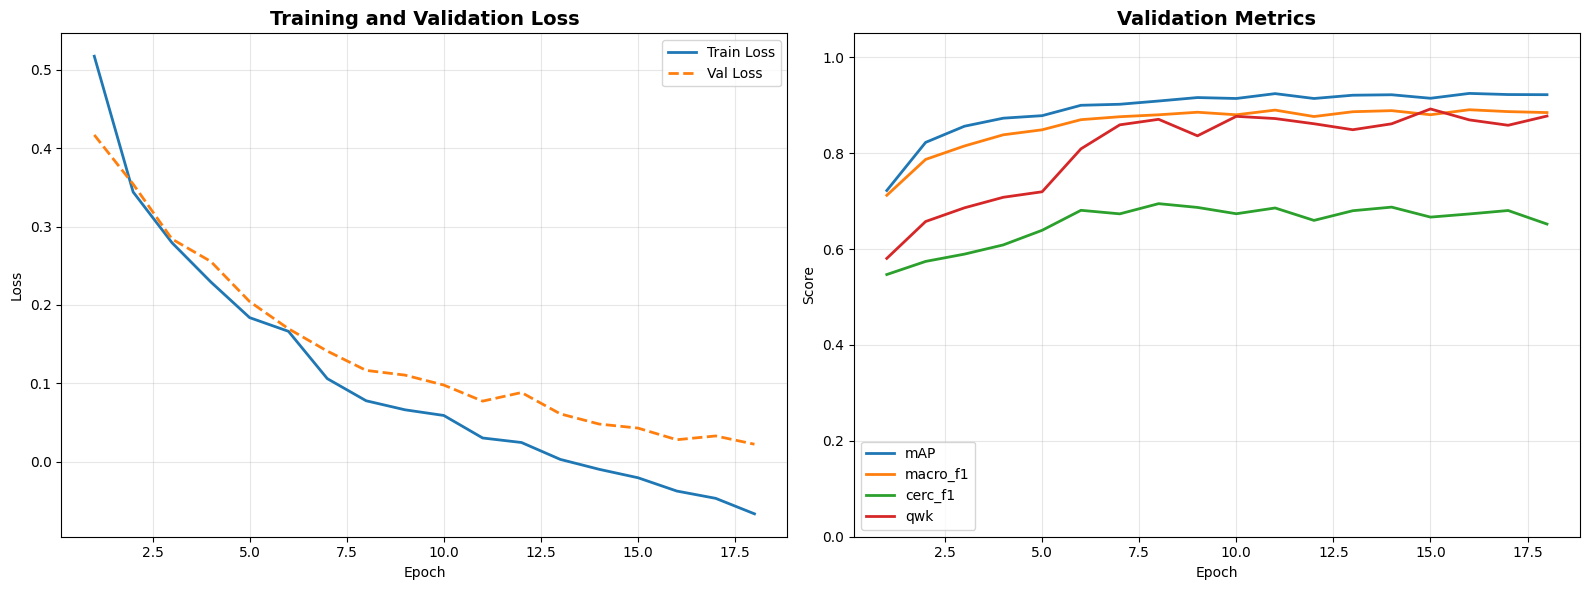

📈 Learning curves saved → /content/drive/MyDrive/checkpoints/v13_1head_0503_1638/learning_curves.png


In [ ]:
import matplotlib.pyplot as plt
def plot_learning_curves(history_df, save_path):
    epochs = history_df["epoch"]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    if "train_loss" in history_df.columns:
        ax1.plot(epochs, history_df["train_loss"], label="Train Loss", lw=2)
    if "val_loss" in history_df.columns:
        ax1.plot(epochs, history_df["val_loss"], label="Val Loss", lw=2, linestyle="--")

    ax1.set_title("Training and Validation Loss", fontsize=14, fontweight="bold")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    metrics_to_plot = [
        "mAP",
        "macro_f1",
        "cerc_f1",
        "qwk",
        "pred_acc",
        "pred_macro_f1",
    ]

    plotted = False
    for metric in metrics_to_plot:
        if metric in history_df.columns:
            ax2.plot(epochs, history_df[metric], label=metric, lw=2)
            plotted = True

    ax2.set_title("Validation Metrics", fontsize=14, fontweight="bold")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Score")
    ax2.set_ylim(0, 1.05)
    if plotted:
        ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"📈 Learning curves saved → {save_path}")


history_df = pd.DataFrame(history)
history_path = f"{SAVE_DIR}/history.csv"
history_df.to_csv(history_path, index=False)
print(f"📊 Training history saved → {history_path}")

plot_learning_curves(history_df, f"{SAVE_DIR}/learning_curves.png")

In [ ]:
ckpt = torch.load(SAVE_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["model_state"])
optimized_thresholds = np.array(ckpt["optimized_thresholds"])

test_res = run_one_epoch(model, test_loader, thresholds=optimized_thresholds)
dm = test_res["disease_metrics"]
sm = test_res["severity_metrics"]
pm = test_res["predominant_metrics"]

# Save raw disease predictions for ROC / PR plotting
np.save(f"{SAVE_DIR}/y_true.npy", dm["y_true"])
np.save(f"{SAVE_DIR}/y_scores.npy", dm["y_prob"])
print(f"💾 Raw disease predictions saved to {SAVE_DIR}/ for ROC/PR plotting.")

# Save raw predominant predictions if available
if pm["y_true"] is not None and pm["y_pred"] is not None:
    np.save(f"{SAVE_DIR}/predominant_y_true.npy", pm["y_true"])
    np.save(f"{SAVE_DIR}/predominant_y_pred.npy", pm["y_pred"])
    print(f"💾 Predominant-stress predictions saved to {SAVE_DIR}/.")

print("\n" + "═" * 56)
print(f"  TEST: {EXP_NAME}")
print("═" * 56)
print(f"  mAP={dm['mAP']:.4f} | MacroF1={dm['macro_f1']:.4f} | mAUC={dm['mAUC']:.4f}")
print(f"  CercF1={dm['cerc_f1']:.4f} | CercRec={dm['cerc_recall']:.4f} | CercPrec={dm['cerc_prec']:.4f}")

if USE_PREDOMINANT_HEAD:
    print(f"  PredAcc={pm['acc']:.4f} | PredMacroF1={pm['macro_f1']:.4f}")

print(f"  MAE={sm['mae']:.4f} | OBO={sm['obo']:.4f} | QWK={sm['qwk']:.4f}")
print("-" * 56)

for cls in DISEASE_COLS:
    f1 = dm["per_class_f1"][cls]
    ap = dm["per_class_ap"][cls]
    f1_str = f"{f1:.4f}" if not np.isnan(f1) else "NaN"
    ap_str = f"{ap:.4f}" if not np.isnan(ap) else "NaN"
    print(f"  {cls:<12}: F1={f1_str} | AP={ap_str}")

if USE_PREDOMINANT_HEAD and pm["per_class_f1"]:
    print("-" * 56)
    print("  Predominant-stress per-class F1:")
    for cls, val in pm["per_class_f1"].items():
        val_str = f"{val:.4f}" if not np.isnan(val) else "NaN"
        print(f"  {cls:<12}: F1={val_str}")

print("═" * 56)


def log_results_csv(exp_name, config, test_res, log_path=LOG_PATH):
    def safe_round(val, d=4):
        try:
            if val is None or pd.isna(val):
                return None
            return round(float(val), d)
        except Exception:
            return None

    dm = test_res["disease_metrics"]
    sm = test_res["severity_metrics"]
    pm = test_res["predominant_metrics"]

    # composite for ranking
    qwk_val = sm.get("qwk", np.nan)
    if pd.isna(qwk_val):
        composite = None
    else:
        composite = 0.4 * dm.get("mAP", np.nan) + 0.3 * dm.get("cerc_f1", np.nan) + 0.3 * qwk_val

    row = {
        "exp_name": exp_name,
        "backbone": CLIP_MODEL,
        "loss_type": config["LOSS_TYPE"],
        "weight_mode": config["LOSS_WEIGHT_MODE"],
        "threshold_mode": config["THRESHOLD_MODE"],
        "unfreeze_n": config["UNFREEZE_LAST_N"],
        "use_text_init": config["USE_TEXT_INIT"],
        "cerc_scale": config["CERC_LOSS_SCALE"],
        "lambda_contrast": config["LAMBDA_CONTRAST"],
        "image_size": config["IMAGE_SIZE"],
        "augment_cerc": config["AUGMENT_CERC"],

        "use_pred_head": config.get("USE_PREDOMINANT_HEAD"),
        "use_gating_fusion": config.get("USE_GATING_FUSION"),
        "sev_detach": config.get("SEV_CONTEXT_DETACH"),
        "use_severity_weighting": config.get("USE_SEVERITY_WEIGHTING"),

        "mAP": safe_round(dm.get("mAP", np.nan)),
        "macro_f1": safe_round(dm.get("macro_f1", np.nan)),
        "mAUC": safe_round(dm.get("mAUC", np.nan)),
        "cerc_f1": safe_round(dm.get("cerc_f1", np.nan)),
        "cerc_recall": safe_round(dm.get("cerc_recall", np.nan)),
        "cerc_prec": safe_round(dm.get("cerc_prec", np.nan)),

        "MAE": safe_round(sm.get("mae", np.nan)),
        "OBO": safe_round(sm.get("obo", np.nan)),
        "QWK": safe_round(sm.get("qwk", np.nan)),

        "pred_acc": safe_round(pm.get("acc", np.nan)),
        "pred_macro_f1": safe_round(pm.get("macro_f1", np.nan)),

        "miner_f1": safe_round(dm.get("per_class_f1", {}).get("miner", np.nan)),
        "rust_f1": safe_round(dm.get("per_class_f1", {}).get("rust", np.nan)),
        "phoma_f1": safe_round(dm.get("per_class_f1", {}).get("phoma", np.nan)),
        "cerc_f1_class": safe_round(dm.get("per_class_f1", {}).get("cercospora", np.nan)),

        "miner_ap": safe_round(dm.get("per_class_ap", {}).get("miner", np.nan)),
        "rust_ap": safe_round(dm.get("per_class_ap", {}).get("rust", np.nan)),
        "phoma_ap": safe_round(dm.get("per_class_ap", {}).get("phoma", np.nan)),
        "cerc_ap": safe_round(dm.get("per_class_ap", {}).get("cercospora", np.nan)),

        "pred_healthy_f1": safe_round(pm.get("per_class_f1", {}).get("healthy", np.nan)),
        "pred_miner_f1": safe_round(pm.get("per_class_f1", {}).get("miner", np.nan)),
        "pred_rust_f1": safe_round(pm.get("per_class_f1", {}).get("rust", np.nan)),
        "pred_phoma_f1": safe_round(pm.get("per_class_f1", {}).get("phoma", np.nan)),
        "pred_cercospora_f1": safe_round(pm.get("per_class_f1", {}).get("cercospora", np.nan)),

        "composite_score": safe_round(composite),
    }

    all_data = []
    if os.path.exists(log_path):
        try:
            with open(log_path, "r", encoding="utf-8") as f:
                reader = csv.DictReader(f)
                for r in reader:
                    if r.get("exp_name") != exp_name:
                        all_data.append(r)
        except Exception as e:
            print(f"⚠️ Lỗi đọc file log cũ: {e}")

    all_data.append(row)

    df_unified = pd.DataFrame(all_data)

    numeric_cols = [
        "mAP", "macro_f1", "mAUC", "cerc_f1", "cerc_recall", "cerc_prec",
        "MAE", "OBO", "QWK",
        "pred_acc", "pred_macro_f1",
        "miner_f1", "rust_f1", "phoma_f1", "cerc_f1_class",
        "miner_ap", "rust_ap", "phoma_ap", "cerc_ap",
        "pred_healthy_f1", "pred_miner_f1", "pred_rust_f1", "pred_phoma_f1", "pred_cercospora_f1",
        "composite_score",
    ]

    for col in numeric_cols:
        if col in df_unified.columns:
            df_unified[col] = pd.to_numeric(df_unified[col], errors="coerce")

    df_unified.to_csv(log_path, index=False)
    print(f"✅ Results merged and updated → {log_path}")


log_results_csv(EXP_NAME, cfg, test_res)

if os.path.exists(LOG_PATH):
    try:
        log_df = pd.read_csv(LOG_PATH)
        rank_col = "composite_score" if "composite_score" in log_df.columns else "cerc_f1"
        print(f"\n📊 BẢNG XẾP HẠNG THÍ NGHIỆM (Ưu tiên {rank_col}):")
        display(log_df.sort_values(rank_col, ascending=False).reset_index(drop=True))
    except Exception as e:
        print(f"⚠️ Lỗi hiển thị bảng: {e}")
        print("Mẹo: Hãy xóa file results_log.csv nếu bạn không cần lịch sử cũ.")

Eval:   0%|          | 0/8 [00:00<?, ?it/s]

💾 Raw disease predictions saved to /content/drive/MyDrive/checkpoints/v13_1head_0503_1638/ for ROC/PR plotting.

════════════════════════════════════════════════════════
  TEST: v13_1head_0503_1638
════════════════════════════════════════════════════════
  mAP=0.9351 | MacroF1=0.8805 | mAUC=0.9755
  CercF1=0.7500 | CercRec=0.8864 | CercPrec=0.6500
  MAE=0.1969 | OBO=0.9843 | QWK=0.8643
--------------------------------------------------------
  healthy     : F1=0.9880 | AP=1.0000
  miner       : F1=0.8296 | AP=0.9357
  rust        : F1=0.8925 | AP=0.9790
  phoma       : F1=0.9423 | AP=0.9822
  cercospora  : F1=0.7500 | AP=0.7787
════════════════════════════════════════════════════════
✅ Results merged and updated → /content/drive/MyDrive/results.csv

📊 BẢNG XẾP HẠNG THÍ NGHIỆM (Ưu tiên composite_score):


,exp_name,backbone,loss_type,weight_mode,threshold_mode,unfreeze_n,use_text_init,cerc_scale,lambda_contrast,image_size,...,miner_ap,rust_ap,phoma_ap,cerc_ap,pred_healthy_f1,pred_miner_f1,pred_rust_f1,pred_phoma_f1,pred_cercospora_f1,composite_score
0,v13_1head_0503_1638,ViT-B-32,asymfocal,uncertainty,optimize,4,True,1.0,0.0,224,...,0.9357,0.9790,0.9822,0.7787,NaN,NaN,NaN,NaN,NaN,0.8583
1,v13_1head_0501_1957,ViT-B-32,asymfocal,uncertainty,optimize,4,True,1.0,0.0,224,...,0.9357,0.9790,0.9822,0.7787,NaN,NaN,NaN,NaN,NaN,0.8583
2,v13_1head_0501_2050,ViT-B-32,asymfocal,uncertainty,optimize,4,True,1.3,0.0,224,...,0.9365,0.9773,0.9829,0.8025,NaN,NaN,NaN,NaN,NaN,0.8562
3,v13_1head_0501_1815,ViT-B-32,asymfocal,uncertainty,optimize,4,True,1.0,0.0,224,...,0.9314,0.9746,0.9790,0.7958,NaN,NaN,NaN,NaN,NaN,0.8525
4,v13_1head_0501_1836,ViT-B-32,asymfocal,uncertainty,optimize,4,True,1.0,0.0,224,...,0.9314,0.9746,0.9790,0.7958,NaN,NaN,NaN,NaN,NaN,0.8525
5,v13_1head_0501_1938,ViT-B-32,asymfocal,uncertainty,optimize,4,True,1.0,0.0,224,...,0.9314,0.9746,0.9790,0.7958,NaN,NaN,NaN,NaN,NaN,0.8525
6,v13_1head_0501_1902,ViT-B-32,asymfocal,uncertainty,optimize,4,True,1.0,0.0,224,...,0.9314,0.9746,0.9790,0.7958,NaN,NaN,NaN,NaN,NaN,0.8525
7,v13_1head_0502_0332,ViT-B-32,asymfocal,uncertainty,optimize,4,True,1.3,0.0,224,...,0.9365,0.9769,0.9829,0.8045,NaN,NaN,NaN,NaN,NaN,0.8524
8,v13_1head_0502_0552,ViT-B-32,asymfocal,uncertainty,optimize,4,False,1.3,0.0,224,...,0.9350,0.9796,0.9845,0.7839,NaN,NaN,NaN,NaN,NaN,0.8522
9,v13_1head_0501_2031,ViT-B-32,asymfocal,uncertainty,optimize,4,True,1.0,0.0,224,...,0.9386,0.9775,0.9828,0.7924,NaN,NaN,NaN,NaN,NaN,0.8520


🚀 Đang thu thập dự đoán từ tập Test...


  0%|          | 0/8 [00:00<?, ?it/s]

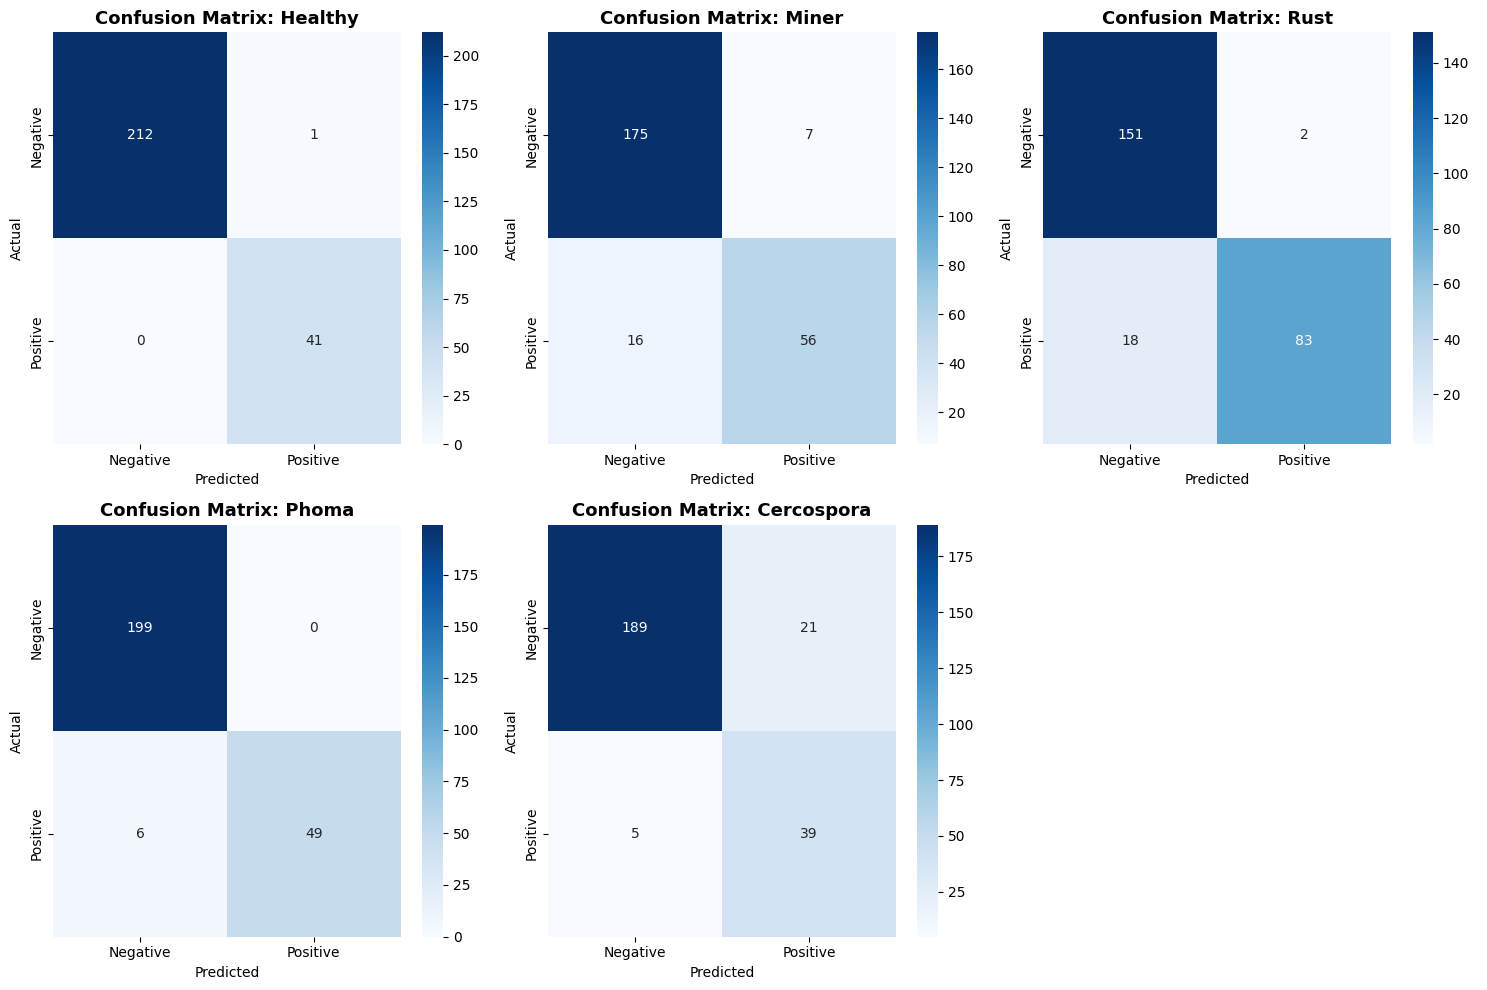

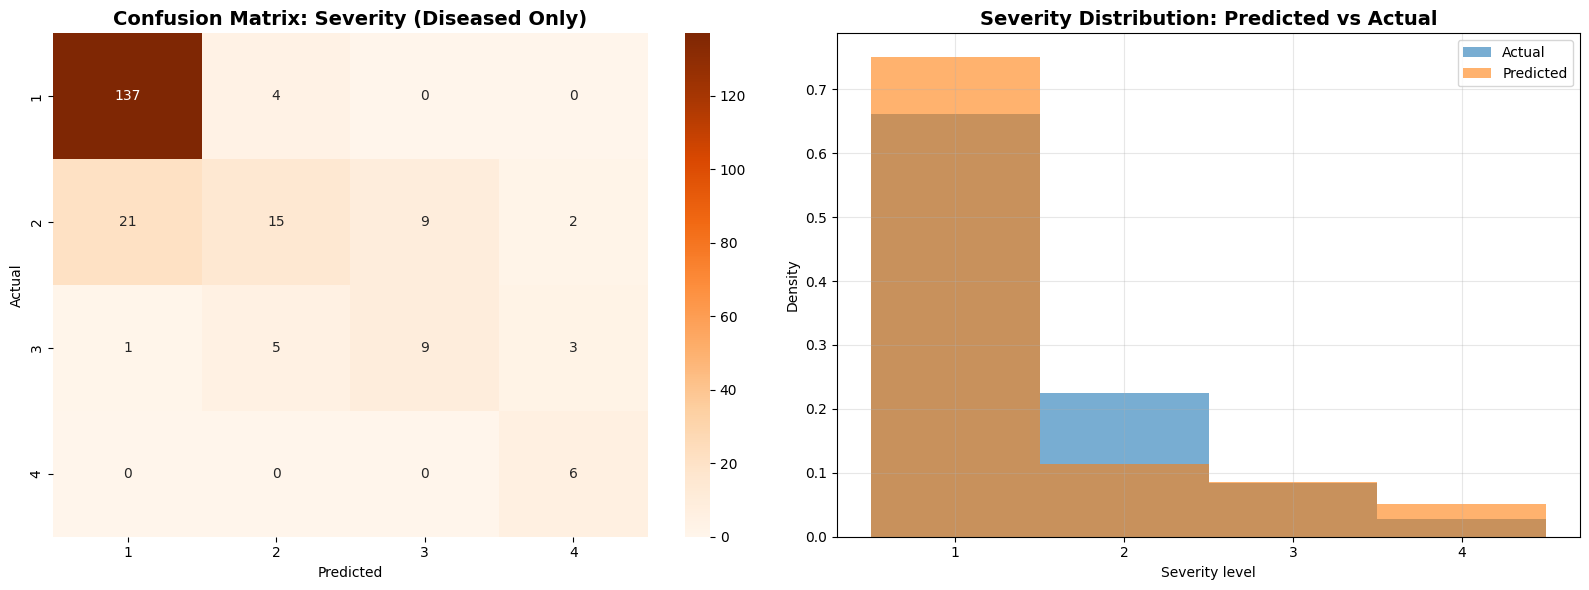

✅ Đã lưu toàn bộ confusion matrices và biểu đồ tại: /content/drive/MyDrive/checkpoints/v13_1head_0503_1638


In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from sklearn.metrics import confusion_matrix

def plot_detailed_metrics(model, dataloader, device, save_dir, disease_thresholds=0.5):
    model.eval()

    all_dis_labels, all_dis_preds = [], []
    all_pred_labels, all_pred_preds = [], []
    all_sev_labels, all_sev_preds = [], []

    print("🚀 Đang thu thập dự đoán từ tập Test...")

    with torch.no_grad():
        for batch in tqdm(dataloader):
            imgs = batch["image"].to(device)
            outputs = model(imgs)

            # =====================================================
            # 1) Disease multi-label - GIỮ NGUYÊN CHO 1 HEAD
            # =====================================================
            dis_probs = torch.sigmoid(outputs["disease_logits"]).cpu().numpy()
            dis_labels = batch["disease_target"].cpu().numpy()  # (B, 5)

            # KHÔNG BỎ HEALTHY - giữ nguyên 5 classes
            if np.isscalar(disease_thresholds):
                dis_preds = (dis_probs >= disease_thresholds).astype(int)
            else:
                # thresholds có 5 giá trị (healthy + 4 bệnh)
                thr = np.array(disease_thresholds).reshape(1, -1)
                dis_preds = (dis_probs >= thr).astype(int)

            all_dis_labels.append(dis_labels)
            all_dis_preds.append(dis_preds)

            # =====================================================
            # 2) Predominant-stress
            # =====================================================
            if "predominant_logits" in outputs:
                pred_logits = outputs["predominant_logits"].cpu().numpy()
                pred_preds = np.argmax(pred_logits, axis=1)
                pred_labels = batch["predominant_stress"].cpu().numpy()

                all_pred_labels.append(pred_labels)
                all_pred_preds.append(pred_preds)

            # =====================================================
            # 3) Severity (chỉ trên diseased samples)
            # =====================================================
            sev_logits = outputs["severity_logits"].cpu()
            sev_probs = torch.sigmoid(sev_logits)
            sev_preds = (sev_probs > 0.5).long().sum(dim=1).cpu().numpy()

            sev_labels = batch["severity_label"].cpu().numpy()
            mask_diseased = (batch["has_disease"].cpu().view(-1).numpy() > 0.5)

            if mask_diseased.any():
                all_sev_labels.extend(sev_labels[mask_diseased])
                all_sev_preds.extend(sev_preds[mask_diseased])


    all_dis_labels = np.vstack(all_dis_labels)  # (N, 5)
    all_dis_preds = np.vstack(all_dis_preds)    # (N, 5)

    if len(all_pred_labels) > 0:
        all_pred_labels = np.concatenate(all_pred_labels)
        all_pred_preds = np.concatenate(all_pred_preds)
    else:
        all_pred_labels = None
        all_pred_preds = None

    all_sev_labels = np.array(all_sev_labels)
    all_sev_preds = np.array(all_sev_preds)

    disease_names = ["Healthy", "Miner", "Rust", "Phoma", "Cercospora"]

    fig1, axes1 = plt.subplots(2, 3, figsize=(15, 10))  # 2x3 cho 5 classes
    axes1 = axes1.flatten()

    for i, disease in enumerate(disease_names):
        cm = confusion_matrix(all_dis_labels[:, i], all_dis_preds[:, i], labels=[0, 1])
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            ax=axes1[i],
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"]
        )
        axes1[i].set_title(f"Confusion Matrix: {disease}", fontsize=13, fontweight="bold")
        axes1[i].set_xlabel("Predicted")
        axes1[i].set_ylabel("Actual")

    # Ẩn subplot thừa (nếu có)
    for j in range(len(disease_names), len(axes1)):
        axes1[j].axis("off")

    plt.tight_layout()
    plt.savefig(f"{save_dir}/confusion_matrices_disease.png", dpi=300, bbox_inches="tight")
    plt.show()

    # =========================================================
    # FIGURE 2: confusion matrix cho predominant-stress
    # =========================================================
    if all_pred_labels is not None:
        class_names = ["Healthy", "Miner", "Rust", "Phoma", "Cercospora"]
        cm_pred = confusion_matrix(all_pred_labels, all_pred_preds, labels=[0, 1, 2, 3, 4])

        plt.figure(figsize=(8, 6))
        sns.heatmap(
            cm_pred,
            annot=True,
            fmt="d",
            cmap="Greens",
            xticklabels=class_names,
            yticklabels=class_names
        )
        plt.title("Confusion Matrix: Predominant Stress", fontsize=14, fontweight="bold")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.tight_layout()
        plt.savefig(f"{save_dir}/confusion_matrix_predominant.png", dpi=300, bbox_inches="tight")
        plt.show()

    fig3, (ax_cm, ax_dist) = plt.subplots(1, 2, figsize=(16, 6))

    unique_labels = sorted(list(set(all_sev_labels.tolist()) | set(all_sev_preds.tolist())))
    if 0 in unique_labels:
        unique_labels.remove(0)

    if len(unique_labels) == 0:
        unique_labels = [1, 2, 3, 4]

    cm_sev = confusion_matrix(all_sev_labels, all_sev_preds, labels=unique_labels)
    sns.heatmap(
        cm_sev,
        annot=True,
        fmt="d",
        cmap="Oranges",
        ax=ax_cm,
        xticklabels=unique_labels,
        yticklabels=unique_labels
    )
    ax_cm.set_title("Confusion Matrix: Severity (Diseased Only)", fontsize=14, fontweight="bold")
    ax_cm.set_xlabel("Predicted")
    ax_cm.set_ylabel("Actual")

    bins = np.arange(0.5, 5.5, 1.0)
    ax_dist.hist(all_sev_labels, bins=bins, alpha=0.6, label="Actual", density=True)
    ax_dist.hist(all_sev_preds, bins=bins, alpha=0.6, label="Predicted", density=True)
    ax_dist.set_title("Severity Distribution: Predicted vs Actual", fontsize=14, fontweight="bold")
    ax_dist.set_xlabel("Severity level")
    ax_dist.set_ylabel("Density")
    ax_dist.set_xticks([1, 2, 3, 4])
    ax_dist.legend()
    ax_dist.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"{save_dir}/severity_analysis.png", dpi=300, bbox_inches="tight")
    plt.show()

    print(f"✅ Đã lưu toàn bộ confusion matrices và biểu đồ tại: {save_dir}")


# Gọi hàm
plot_detailed_metrics(
    model,
    test_loader,
    DEVICE,
    SAVE_DIR,
    disease_thresholds=optimized_thresholds if 'optimized_thresholds' in globals() else 0.5
)

Extracting disease predictions:   0%|          | 0/8 [00:00<?, ?it/s]

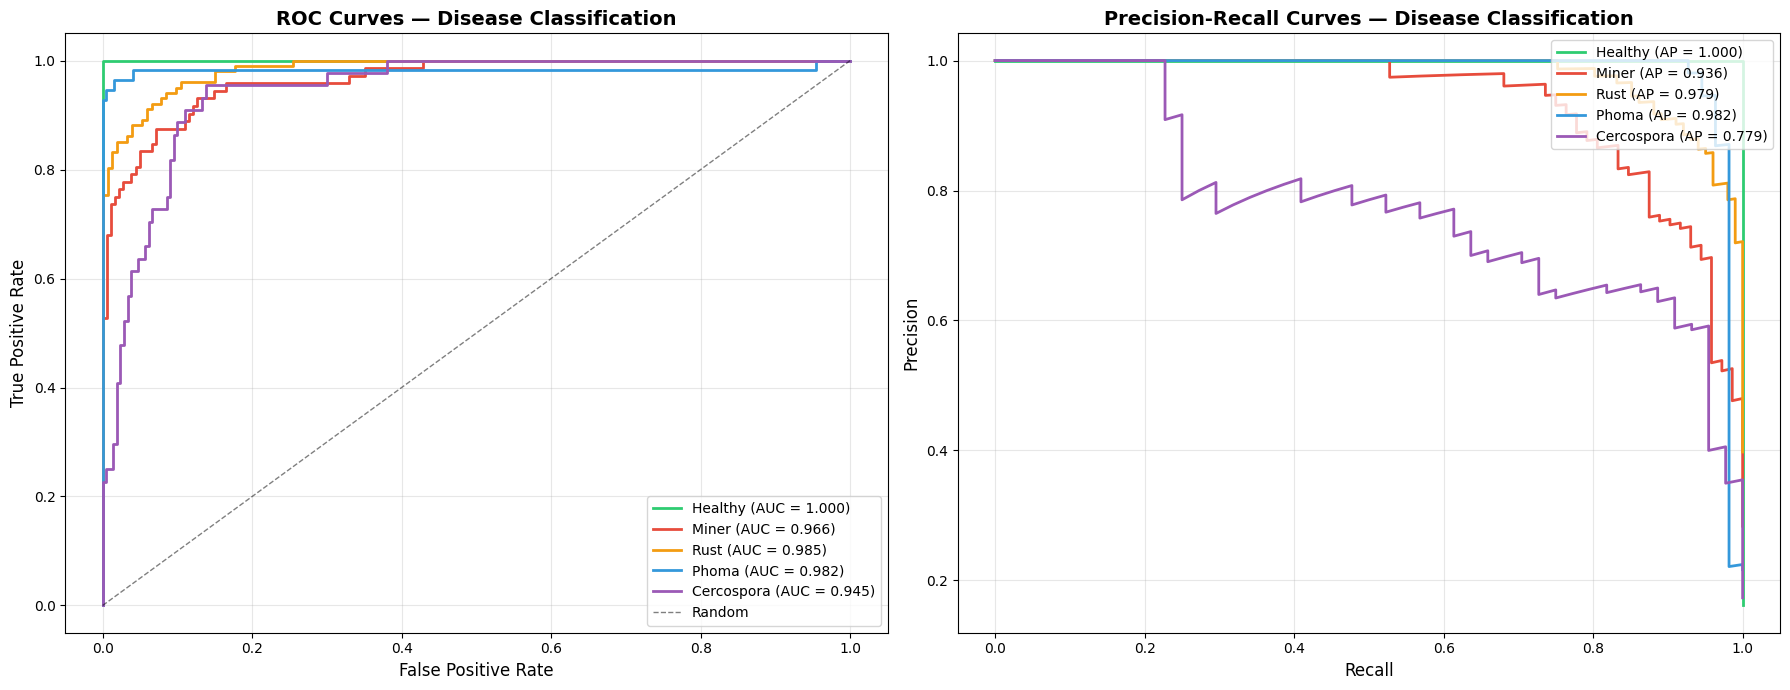

✅ Đã lưu ROC & PR curves tại: /content/drive/MyDrive/checkpoints/v13_1head_0503_1638/roc_pr_curves.png


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from tqdm.auto import tqdm

def plot_roc_pr_curves(model, dataloader, device, save_dir):
    model.eval()

    all_dis_probs, all_dis_labels = [], []

    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Extracting disease predictions"):
            imgs = batch["image"].to(device)
            outputs = model(imgs)

            dis_probs = torch.sigmoid(outputs["disease_logits"]).cpu().numpy()
            dis_labels = batch["disease_target"].numpy()

            all_dis_probs.append(dis_probs)
            all_dis_labels.append(dis_labels)

    all_dis_probs = np.vstack(all_dis_probs)    # (N, 5)
    all_dis_labels = np.vstack(all_dis_labels)  # (N, 5)

    # BAO GỒM CẢ HEALTHY
    disease_names = ["Healthy", "Miner", "Rust", "Phoma", "Cercospora"]
    colors = ["#2ecc71", "#e74c3c", "#f39c12", "#3498db", "#9b59b6"]

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    # =========================================================
    # FIGURE 1: ROC Curves
    # =========================================================
    ax_roc = axes[0]

    for i, (name, color) in enumerate(zip(disease_names, colors)):
        y_true = all_dis_labels[:, i]
        y_score = all_dis_probs[:, i]

        if len(np.unique(y_true)) < 2:
            print(f"⚠️ Skip ROC for {name}: only one class present in y_true.")
            continue

        fpr, tpr, _ = roc_curve(y_true, y_score)
        roc_auc = auc(fpr, tpr)
        ax_roc.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC = {roc_auc:.3f})")

    ax_roc.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5, label="Random")
    ax_roc.set_xlabel("False Positive Rate", fontsize=12)
    ax_roc.set_ylabel("True Positive Rate", fontsize=12)
    ax_roc.set_title("ROC Curves — Disease Classification", fontsize=14, fontweight="bold")
    ax_roc.legend(loc="lower right", fontsize=10)
    ax_roc.grid(True, alpha=0.3)

    # =========================================================
    # FIGURE 2: Precision-Recall Curves
    # =========================================================
    ax_pr = axes[1]

    for i, (name, color) in enumerate(zip(disease_names, colors)):
        y_true = all_dis_labels[:, i]
        y_score = all_dis_probs[:, i]

        if y_true.sum() == 0:
            print(f"⚠️ Skip PR for {name}: no positive samples in y_true.")
            continue

        precision, recall, _ = precision_recall_curve(y_true, y_score)
        ap = average_precision_score(y_true, y_score)
        ax_pr.plot(recall, precision, color=color, lw=2, label=f"{name} (AP = {ap:.3f})")

    ax_pr.set_xlabel("Recall", fontsize=12)
    ax_pr.set_ylabel("Precision", fontsize=12)
    ax_pr.set_title("Precision-Recall Curves — Disease Classification", fontsize=14, fontweight="bold")
    ax_pr.legend(loc="upper right", fontsize=10)
    ax_pr.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"{save_dir}/roc_pr_curves.png", dpi=300, bbox_inches="tight")
    plt.show()

    print(f"✅ Đã lưu ROC & PR curves tại: {save_dir}/roc_pr_curves.png")


plot_roc_pr_curves(model, test_loader, DEVICE, SAVE_DIR)

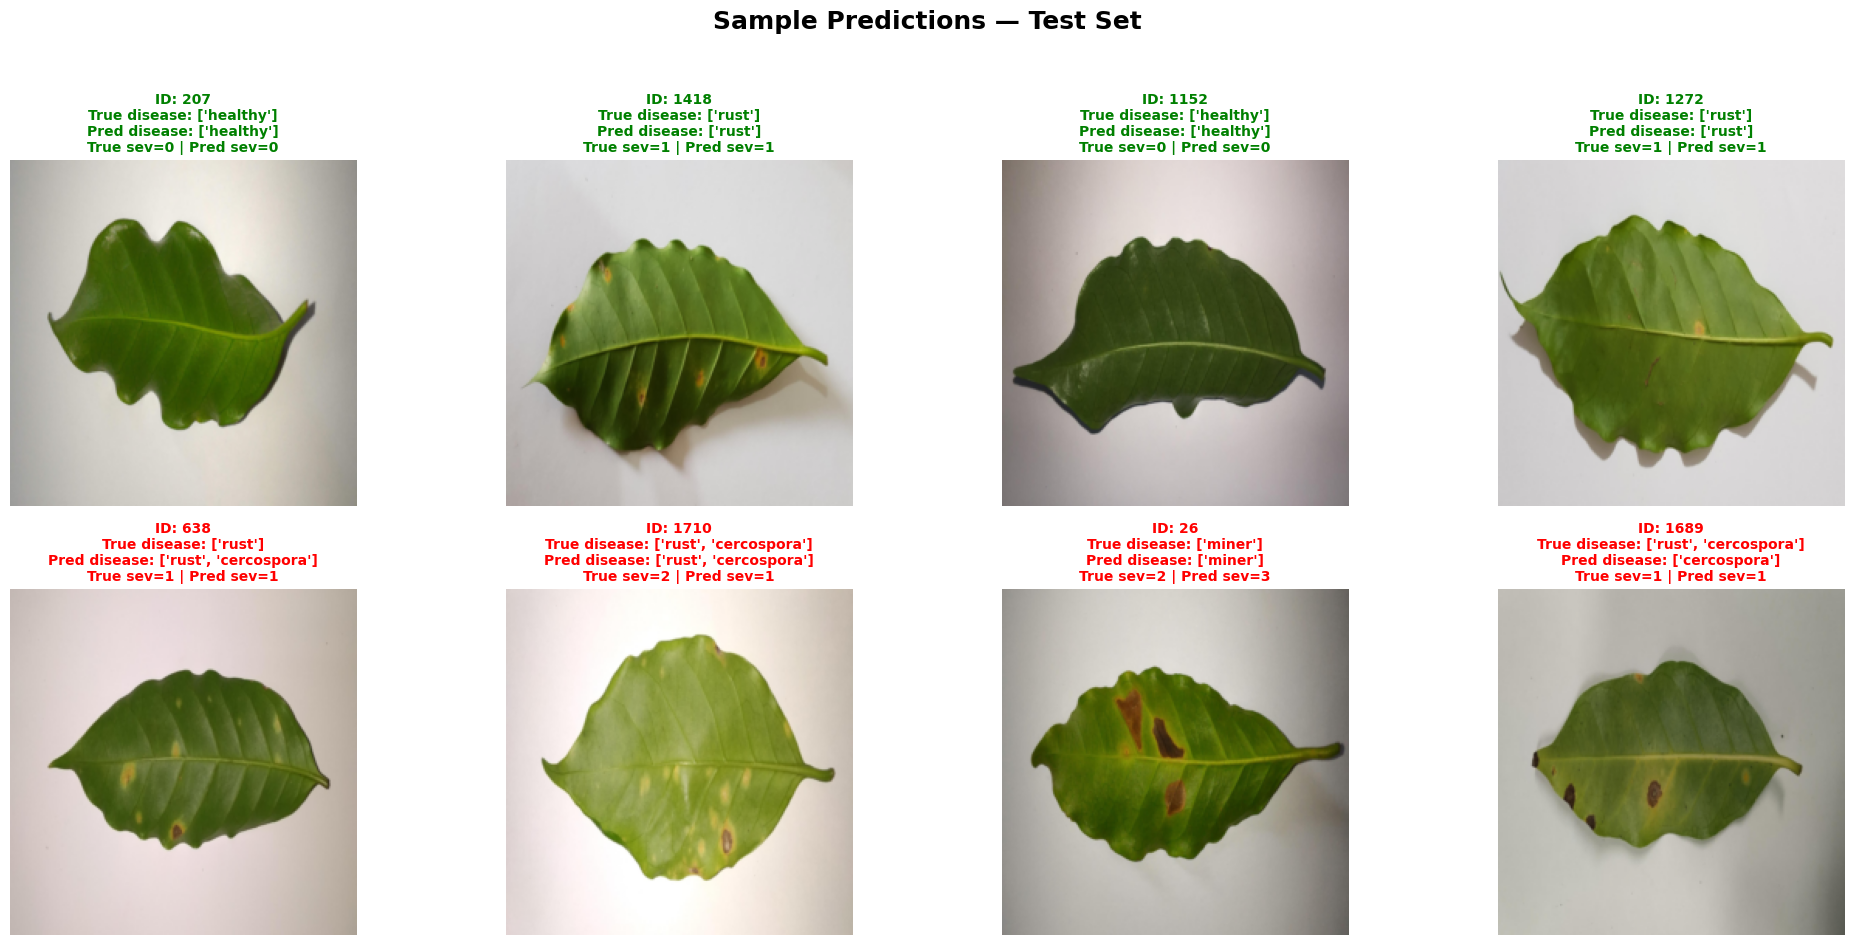

✅ Đã lưu sample predictions tại: /content/drive/MyDrive/checkpoints/v13_1head_0503_1638/sample_predictions_v13.png


In [ ]:
import os
import math
import torch
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

def plot_sample_predictions_v13(
    model,
    dataloader,
    device,
    save_dir,
    disease_thresholds=0.5,
    num_correct=4,
    num_incorrect=4,
    max_batches=None,
):
    model.eval()
    os.makedirs(save_dir, exist_ok=True)

    disease_names = ["healthy", "miner", "rust", "phoma", "cercospora"]
    pred_names = ["healthy", "miner", "rust", "phoma", "cercospora"]

    correct_cases = []
    incorrect_cases = []

    mean = np.array([0.48145466, 0.4578275, 0.40821073], dtype=np.float32)
    std = np.array([0.26862954, 0.26130258, 0.27577711], dtype=np.float32)

    def denormalize(img_tensor):
        img = img_tensor.detach().cpu().numpy().transpose(1, 2, 0)
        img = img * std + mean
        img = np.clip(img, 0, 1)
        return img

    def multilabel_to_names(vec):
        """vec có 5 phần tử: healthy, miner, rust, phoma, cercospora"""
        # Nếu healthy = 1 và không có bệnh nào
        if vec[0] == 1 and vec[1:].sum() == 0:
            return ["healthy"]
        # Nếu có bệnh
        names = []
        if vec[1] == 1:
            names.append("miner")
        if vec[2] == 1:
            names.append("rust")
        if vec[3] == 1:
            names.append("phoma")
        if vec[4] == 1:
            names.append("cercospora")
        return names if len(names) > 0 else ["healthy"]

    def severity_from_logits(sev_logits_tensor):
        sev_probs = torch.sigmoid(sev_logits_tensor)
        sev_pred = (sev_probs > 0.5).long().sum(dim=1)
        return sev_pred.cpu().numpy()

    with torch.no_grad():
        for b_idx, batch in enumerate(tqdm(dataloader, desc="Collecting sample predictions")):
            if max_batches is not None and b_idx >= max_batches:
                break

            images = batch["image"].to(device)
            outputs = model(images)

            # Disease predictions (5 classes: healthy + 4 bệnh)
            dis_probs = torch.sigmoid(outputs["disease_logits"]).cpu().numpy()

            if np.isscalar(disease_thresholds):
                dis_preds = (dis_probs >= disease_thresholds).astype(int)
            else:
                thr = np.array(disease_thresholds).reshape(1, -1)
                dis_preds = (dis_probs >= thr).astype(int)

            sev_preds = severity_from_logits(outputs["severity_logits"])

            dis_true = batch["disease_target"].cpu().numpy().astype(int)  # (B, 5)
            sev_true = batch["severity_label"].cpu().numpy().astype(int)

            for i in range(images.size(0)):
                img = denormalize(images[i])

                true_d_names = multilabel_to_names(dis_true[i])
                pred_d_names = multilabel_to_names(dis_preds[i])

                sev_t = int(sev_true[i])
                sev_p = int(sev_preds[i])

                disease_correct = np.array_equal(dis_true[i], dis_preds[i])
                sev_correct = (sev_t == sev_p)

                overall_correct = disease_correct and sev_correct

                case = {
                    "image": img,
                    "true_disease": true_d_names,
                    "pred_disease": pred_d_names,
                    "true_severity": sev_t,
                    "pred_severity": sev_p,
                    "overall_correct": overall_correct,
                    "image_id": batch["image_id"][i] if "image_id" in batch else f"sample_{b_idx}_{i}",
                }

                if overall_correct and len(correct_cases) < num_correct:
                    correct_cases.append(case)
                elif (not overall_correct) and len(incorrect_cases) < num_incorrect:
                    incorrect_cases.append(case)

                if len(correct_cases) >= num_correct and len(incorrect_cases) >= num_incorrect:
                    break

            if len(correct_cases) >= num_correct and len(incorrect_cases) >= num_incorrect:
                break

    selected_cases = correct_cases + incorrect_cases

    if len(selected_cases) == 0:
        print("⚠️ Không thu được sample predictions nào để vẽ.")
        return

    n = len(selected_cases)
    ncols = 4
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.8 * nrows))
    if nrows == 1:
        axes = np.array(axes).reshape(1, -1)

    fig.suptitle("Sample Predictions — Test Set", fontsize=18, fontweight="bold")

    for ax in axes.flatten():
        ax.axis("off")

    for idx, case in enumerate(selected_cases):
        r, c = divmod(idx, ncols)
        ax = axes[r, c]

        ax.imshow(case["image"])
        ax.axis("off")

        is_correct = case["overall_correct"]
        color = "green" if is_correct else "red"

        title_1 = f"ID: {case['image_id']}"
        title_2 = f"True disease: {case['true_disease']}\nPred disease: {case['pred_disease']}"
        title_3 = f"True sev={case['true_severity']} | Pred sev={case['pred_severity']}"

        ax.set_title(
            title_1 + "\n" + title_2 + "\n" + title_3,
            fontsize=10,
            color=color,
            fontweight="bold"
        )

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    out_path = os.path.join(save_dir, "sample_predictions_v13.png")
    plt.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"✅ Đã lưu sample predictions tại: {out_path}")


plot_sample_predictions_v13(
    model,
    test_loader,
    DEVICE,
    SAVE_DIR,
    disease_thresholds=optimized_thresholds if "optimized_thresholds" in globals() else 0.5,
    num_correct=4,
    num_incorrect=4,
)

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

def generate_academic_report(y_true, y_pred, target_names):
    """
    Tạo báo cáo kết quả học thuật định dạng chuẩn Classification Report.
    """

    report_dict = classification_report(
        y_true,
        y_pred,
        target_names=target_names,
        output_dict=True,
        zero_division=0
    )

    # In ra terminal với định dạng string chuẩn
    print("\n=== ACADEMIC REPORT: CLIP Optimized ===")
    print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))

    # Ngoài ra, bạn có thể lưu thành DataFrame để xuất ra CSV hoặc Excel
    report_df = pd.DataFrame(report_dict).transpose()
    return report_df

y_true_disease = test_res["disease_metrics"]["y_true"]
y_pred_disease = (test_res["disease_metrics"]["y_prob"] > optimized_thresholds).astype(int)

# Gọi hàm để in báo cáo
report_df = generate_academic_report(
    y_true_disease,
    y_pred_disease,
    target_names=DISEASE_COLS
)

# Lưu báo cáo vào thư mục kết quả
report_df.to_csv(f"{SAVE_DIR}/classification_report.csv")
print(f"📊 Chi tiết báo cáo đã được lưu tại {SAVE_DIR}/classification_report.csv")


=== ACADEMIC REPORT: CLIP Optimized ===
              precision    recall  f1-score   support

     healthy       0.98      1.00      0.99        41
       miner       0.89      0.78      0.83        72
        rust       0.98      0.82      0.89       101
       phoma       1.00      0.89      0.94        55
  cercospora       0.65      0.89      0.75        44

   micro avg       0.90      0.86      0.88       313
   macro avg       0.90      0.88      0.88       313
weighted avg       0.91      0.86      0.88       313
 samples avg       0.92      0.89      0.89       313

📊 Chi tiết báo cáo đã được lưu tại /content/drive/MyDrive/checkpoints/v13_1head_0503_1638/classification_report.csv


In [ ]:
!pip install clip opencv-python matplotlib pillow grad-cam

  Preparing metadata (setup.py) ... done
  Created wheel for clip: filename=clip-0.2.0-py3-none-any.whl size=6989 sha256=ee1b6500409fb1b45224e6d127ac7dc1d44ca2313e7de02f2d5956cd808b6975
  Stored in directory: /root/.cache/pip/wheels/6c/fd/54/9d4e15cf829b871199a7cd3597e869a514d1624a0a43076896
Successfully built clip


open_clip version: 3.3.0
Device: cuda
Checkpoint exists: True
Image exists: True
Detected 5 disease classes from checkpoint
✅ Model initialized:
   Disease classes: 5
   Severity input dim: 262
   Gating fusion: True
✅ Model loaded from /content/drive/MyDrive/checkpoints/v13_1head_0503_1638/model.pt

📊 Predictions for 1545.jpg:
   healthy: 11.2%
   miner: 73.5%
   rust: 86.2%
   phoma: 17.6%
   cercospora: 79.2%
   Severity level: 3/4


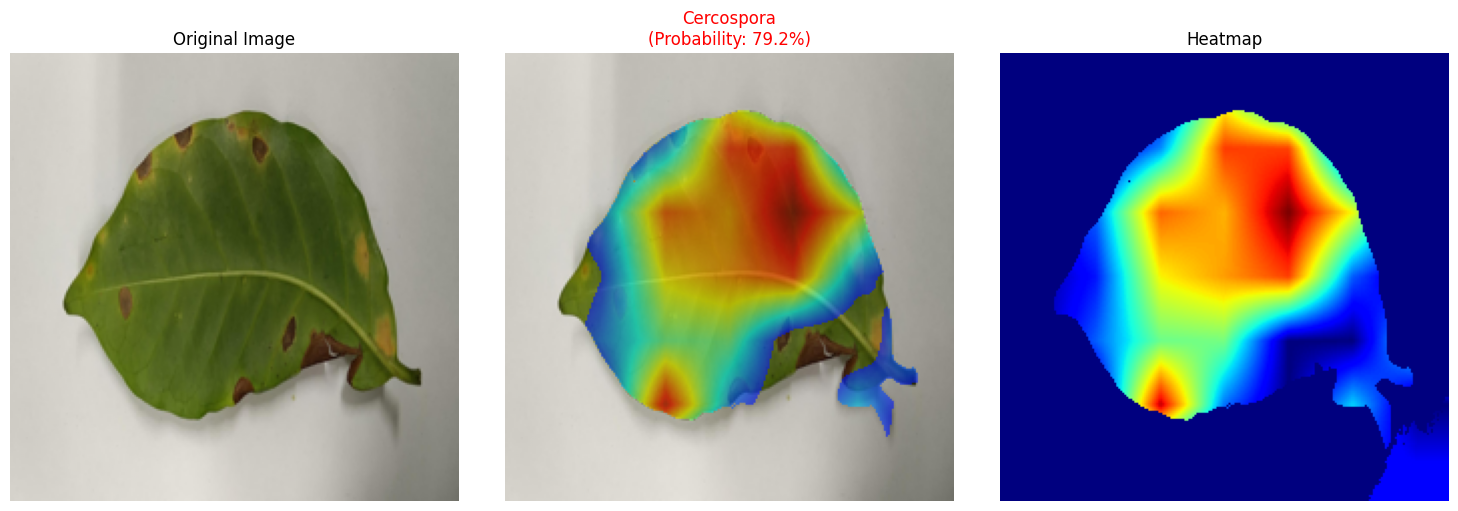

In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import open_clip

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print(f"open_clip version: {open_clip.__version__}")


class CLIPMultiTaskModel(nn.Module):
    def __init__(
        self,
        clip_model_name="ViT-B-32",
        pretrained="openai",
        num_disease=5,  # ← 5 classes (healthy + 4 diseases)
        num_sev_nodes=4,
        use_text_init=False,
        use_predominant_head=False,
        use_gating_fusion=True,
        use_single_head=True,
        sev_context_detach=True,
        device="cpu",
    ):
        super().__init__()

        clip_model, _, _ = open_clip.create_model_and_transforms(
            clip_model_name, pretrained=pretrained
        )
        clip_model = clip_model.to(device)

        self.num_disease = num_disease
        self.num_sev_nodes = num_sev_nodes
        self.use_text_init = use_text_init
        self.use_predominant_head = use_predominant_head
        self.use_gating_fusion = use_gating_fusion
        self.use_single_head = use_single_head
        self.sev_context_detach = sev_context_detach

        self.visual_encoder = clip_model.visual
        self.severity_offset = nn.Parameter(torch.tensor(0.0), requires_grad=False)

        feat_dim = getattr(self.visual_encoder, "output_dim", 512)

        self.disease_pre_head = nn.Sequential(
            nn.Linear(feat_dim, feat_dim),
            nn.LayerNorm(feat_dim),
            nn.GELU(),
            nn.Dropout(0.2)
        )

        self.disease_classifier = nn.Linear(feat_dim, num_disease)
        self.logit_scale = nn.Parameter(torch.tensor(2.71).log())

        # Severity head - MUST MATCH checkpoint
        self.severity_pre_head = nn.Sequential(
            nn.Linear(feat_dim, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.2)
        )

        # Calculate sev_in_dim to match checkpoint (262)
        sev_in_dim = 256 + num_disease  # 256 + 5 = 261
        if use_gating_fusion:
            sev_in_dim += 1

        self.severity_head = nn.Sequential(
            nn.Linear(sev_in_dim, 128),  # (262, 128) ✅
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)  # Output 1 node
        )

        self.severity_deltas = nn.Parameter(torch.zeros(num_sev_nodes))
        self.predominant_head = None

        del clip_model

        print(f"✅ Model initialized:")
        print(f"   Disease classes: {num_disease}")
        print(f"   Severity input dim: {sev_in_dim}")
        print(f"   Gating fusion: {use_gating_fusion}")

    def forward(self, x):
        visual_feat = self.visual_encoder(x)

        # Disease branch
        disease_feat = self.disease_pre_head(visual_feat)

        feat_norm = disease_feat / (disease_feat.norm(dim=-1, keepdim=True) + 1e-6)
        scale = self.logit_scale.exp().clamp(max=100)
        disease_logits = self.disease_classifier(feat_norm) * scale
        disease_probs = torch.sigmoid(disease_logits)

        # Gating signal from healthy class (class 0)
        if self.use_single_head and disease_probs.size(1) >= 5:
            p_healthy = disease_probs[:, 0:1]
            gating_signal = 1.0 - p_healthy
        else:
            gating_signal = None

        # Context for severity
        d_ctx = disease_probs
        g_ctx = gating_signal

        if self.sev_context_detach:
            d_ctx = d_ctx.detach()
            if g_ctx is not None:
                g_ctx = g_ctx.detach()

        # Severity branch
        sev_visual_feat = self.severity_pre_head(visual_feat)

        if self.use_gating_fusion and g_ctx is not None:
            sev_input = torch.cat([sev_visual_feat, d_ctx, g_ctx], dim=-1)
        else:
            sev_input = torch.cat([sev_visual_feat, d_ctx], dim=-1)

        sorted_thresholds = torch.cumsum(F.softplus(self.severity_deltas), dim=0) - self.severity_offset
        sev_score = self.severity_head(sev_input)
        severity_logits = sev_score - sorted_thresholds

        return {
            "features": visual_feat,
            "disease_logits": disease_logits,
            "severity_logits": severity_logits,
        }


# ==========================================
# Load model from checkpoint
# ==========================================
def load_model(checkpoint_path, device):
    """Load model from checkpoint - auto detect number of classes"""

    # First peek at checkpoint to determine num_disease
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    state_dict = checkpoint["model_state"] if "model_state" in checkpoint else checkpoint

    # Get number of disease classes from checkpoint
    disease_weight_shape = state_dict["disease_classifier.weight"].shape
    num_disease = disease_weight_shape[0]
    print(f"Detected {num_disease} disease classes from checkpoint")

    # Create model with correct num_disease
    model = CLIPMultiTaskModel(
        num_disease=num_disease,
        num_sev_nodes=4,
        use_text_init=False,
        use_predominant_head=False,
        use_gating_fusion=True,
        use_single_head=True,
        sev_context_detach=True,
        device=device
    ).to(device)

    # Load state dict
    model.load_state_dict(state_dict, strict=True)
    model.eval()

    print(f"✅ Model loaded from {checkpoint_path}")
    return model, num_disease


# ==========================================
# Grad-CAM Visualization
# ==========================================
def reshape_transform_vit(tensor):
    """Reshape ViT features for CAM"""
    tensor = tensor[:, 1:, :]  # Remove CLS token -> [B, 49, C]
    tensor = tensor.reshape(tensor.size(0), 7, 7, tensor.size(2))  # [B, 7, 7, C]
    tensor = tensor.permute(0, 3, 1, 2)  # [B, C, 7, 7]
    return tensor


def visualize_gradcam(model, image_path, disease_idx, disease_name, disease_cols, device):
    """Visualize Grad-CAM for a specific disease"""

    # CLIP preprocessing
    mean = (0.48145466, 0.4578275, 0.40821073)
    std = (0.26862954, 0.26130258, 0.27577711)

    transform = T.Compose([
        T.Resize((224, 224)),
        T.ToTensor(),
        T.Normalize(mean=mean, std=std)
    ])

    # Load and preprocess image
    original_img = Image.open(image_path).convert("RGB")
    original_img_np = np.array(original_img.resize((224, 224))) / 255.0
    input_tensor = transform(original_img).unsqueeze(0).to(device)
    input_tensor.requires_grad = True

    # Get predictions
    with torch.no_grad():
        outputs = model(input_tensor)
        disease_probs = torch.sigmoid(outputs["disease_logits"]).cpu().numpy()[0]
        severity_logits = outputs["severity_logits"].cpu().numpy()[0]
        severity_level = np.argmin(severity_logits)

    print(f"\n📊 Predictions for {os.path.basename(image_path)}:")
    for i, (name, prob) in enumerate(zip(disease_cols, disease_probs)):
        print(f"   {name}: {prob*100:.1f}%")
    print(f"   Severity level: {severity_level}/4")

    # Wrap model for disease output
    class Wrapper(nn.Module):
        def __init__(self, m):
            super().__init__()
            self.model = m
        def forward(self, x):
            return self.model(x)["disease_logits"]

    wrapped = Wrapper(model).to(device)
    wrapped.eval()

    # Target layer (last transformer block)
    target_layers = [model.visual_encoder.transformer.resblocks[-1].ln_1]

    # Create CAM
    cam = GradCAM(
        model=wrapped,
        target_layers=target_layers,
        reshape_transform=reshape_transform_vit
    )

    targets = [ClassifierOutputTarget(disease_idx)]

    with torch.enable_grad():
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)

    grayscale_cam = grayscale_cam[0, :]
    grayscale_cam = cv2.resize(grayscale_cam, (224, 224))
    grayscale_cam = (grayscale_cam - grayscale_cam.min()) / (grayscale_cam.max() - grayscale_cam.min() + 1e-8)

    # Leaf masking
    gray = cv2.cvtColor((original_img_np * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    _, leaf_mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    if np.mean(gray[leaf_mask == 255]) > np.mean(gray[leaf_mask == 0]):
        leaf_mask = cv2.bitwise_not(leaf_mask)

    leaf_mask_bool = leaf_mask > 0
    grayscale_cam[~leaf_mask_bool] = 0

    if grayscale_cam.max() > grayscale_cam.min():
        grayscale_cam = (grayscale_cam - grayscale_cam.min()) / (grayscale_cam.max() - grayscale_cam.min() + 1e-8)

    # Create overlay
    heatmap = cv2.applyColorMap(np.uint8(255 * grayscale_cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    overlay = original_img_np.copy()
    mask = grayscale_cam > 0.15
    overlay[mask] = 0.4 * original_img_np[mask] + 0.6 * (heatmap[mask] / 255.0)

    # Display
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(original_img_np)
    axes[0].set_title("Original Image", fontsize=12)
    axes[0].axis('off')

    axes[1].imshow(overlay)
    axes[1].set_title(f"{disease_name}\n(Probability: {disease_probs[disease_idx]*100:.1f}%)",
                      color='red' if disease_probs[disease_idx] > 0.5 else 'black')
    axes[1].axis('off')

    axes[2].imshow(grayscale_cam, cmap='jet')
    axes[2].set_title("Heatmap", fontsize=12)
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    return grayscale_cam, overlay


if __name__ == "__main__":
    # ⚠️ UPDATE THESE PATHS ⚠️
    CHECKPOINT_PATH = "/content/drive/MyDrive/checkpoints/v13_1head_0503_1638/model.pt"
    SAMPLE_IMG = "/content/drive/MyDrive/coffee-datasets/coffee-datasets/leaf/images/1545.jpg"

          # YOUR PATH
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

    # Disease columns for 5 classes (healthy + 4 diseases)
    DISEASE_COLS = ['healthy', 'miner', 'rust', 'phoma', 'cercospora']

    print(f"Device: {DEVICE}")
    print(f"Checkpoint exists: {os.path.exists(CHECKPOINT_PATH)}")
    print(f"Image exists: {os.path.exists(SAMPLE_IMG)}")

    if os.path.exists(CHECKPOINT_PATH) and os.path.exists(SAMPLE_IMG):
        model, num_disease = load_model(CHECKPOINT_PATH, DEVICE)

        # Cercospora index is 4 (0: healthy, 1: miner, 2: rust, 3: phoma, 4: cercospora)
        cerc_idx = DISEASE_COLS.index('cercospora')  # Should be 4

        visualize_gradcam(model, SAMPLE_IMG, cerc_idx, "Cercospora", DISEASE_COLS, DEVICE)
    else:
        print("\n❌ Please update CHECKPOINT_PATH and SAMPLE_IMG to actual paths")

In [ ]:
class SeverityModelWrapper(torch.nn.Module):
    """Wrapper to extract severity output for CAM"""
    def __init__(self, original_model):
        super().__init__()
        self.model = original_model

    def forward(self, x):
        outputs = self.model(x)
        # Get severity logits
        # severity_logits shape: [batch, num_sev_nodes] (4 nodes for 5 levels)
        severity_logits = outputs["severity_logits"]
        # Convert to single score if needed (sum over thresholds)
        # For CORAL: lower threshold -> higher severity
        severity_score = -torch.sum(severity_logits, dim=1, keepdim=True)
        return severity_score
